## 02 Data Cleaning

#### Purpose
- Investigate the data sanity and quality 
- Clean the data

#### Steps: 
- DuckDB setup and memory limits
- Data-quality audit of the raw data (dtypes, statistics, true nulls and placeholder values, invalid codes, impossible values, constant columns)
- Cleaning rules: policies
- Cleaning rules: claims
- Cleaning rules: disasters, community, ACS, FRED
- Before/after counts and cleaning_log.csv
- Export cleaned parquet

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III. 

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-12

### Section 0. Load the libraries and working directory

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import DICTIONARIES, DOCS, PROCESSED, RAW_CENSUS, RAW_FRED, REPORTS, ensure_dirs
from src.db import connect, drop_views, register_raw_views, scalar
from src.download import ACS_VARS, FRED_SERIES
from src.dictionary import ZONE_PATTERN, add_allowed, coded_columns, compare_types, map_type
from src.dates import FLAGS, parse_dates, parse_mmddyy, parse_with_flags
from src.dq import (METADATA_COLUMNS, PLACEHOLDERS, CleaningLog, audit_invalid, audit_missing,
                    check_allowed_values, compare_rows, count_duplicates, duplicate_examples,
                    null_profile, review_invalid, run_rules, sql_list, suggest_null_treatment,
                    summarize_allowed)
from src.clean import (ACS_SENTINELS, dedup_sql, draft_decision, fred_to_monthly, invalid_code_flags,
                       log_table_fixes, make_select, rule_flags)
from src.geo import community_id6, padded, register_state_fips

ensure_dirs()   # creates data/interim, data/processed, reports and docs/data_dictionary if missing

### Section 1. Load the datasets
Our datasets include the following (all downloaded in full, unchanged, into data/raw/):
1. NFIP Redacted Policies v3: about 74.7M policy terms (OpenFEMA bulk Parquet)
2. NFIP Redacted Claims v3: about 2.7M claims (OpenFEMA bulk Parquet)
3. Disaster Declarations Summaries (OpenFEMA)
4. NFIP Community Status Book (OpenFEMA)
5. FRED macroeconomic series
6. Census ACS 5-year (2022), tract level

We also need to load the data dictionaries: 
1. fema_NfipCommunityStatusBook_v1.xlsx
2. census_acs5_2022_selected.xlsx
3. fema_DisasterDeclarationsSummaries_v2.xlsx
4. fema_NfipClaims_v3.xlsx
5. fema_NfipPolicies_v3.xlsx

In [2]:
# Open a DuckDB connection (memory limit + spill folder) and one view per raw Parquet file
con = connect(memory_limit="8GB")
drop_views(con, ["raw_policies_fixed", "raw_claims_fixed"])   # left over from an earlier version of this notebook
register_raw_views(con)

,name
0,clean_claims
1,clean_community
2,clean_disasters
3,clean_policies
4,dedup_claims
5,dedup_disasters
6,dedup_policies
7,raw_claims
8,raw_community
9,raw_disasters


In [3]:
# Load the FRED series (one DataFrame per series ID)
fred = {sid: pd.read_csv(RAW_FRED / f"{sid}.csv") for sid in FRED_SERIES}
{sid: df.shape for sid, df in fred.items()}

{'MORTGAGE30US': (2902, 2),
 'DGS10': (16918, 2),
 'UNRATE': (946, 2),
 'CPIAUCSL': (957, 2),
 'CSUSHPINSA': (476, 2),
 'FEDFUNDS': (868, 2)}

In [4]:
# Load the Census ACS tract estimates
acs = pd.read_csv(RAW_CENSUS / "acs5_2022_tract.csv")
acs.head(5).T

,0,1,2,3,4
NAME,Census Tract 201; Autauga County; Alabama,Census Tract 202; Autauga County; Alabama,Census Tract 203; Autauga County; Alabama,Census Tract 204; Autauga County; Alabama,Census Tract 205.01; Autauga County; Alabama
median_household_income,60563,57460,77371,73191,79953
median_home_value,162000,128200,137400,171200,179800
median_age,38.9,41.1,36.8,45.0,39.3
occupied_housing_units,700,544,1305,1666,1783
owner_occupied_units,519,429,912,1306,971
total_population,1865,1861,3492,3987,4121
state,1,1,1,1,1
county,1,1,1,1,1
tract,20100,20200,20300,20400,20501


In [5]:
# Create the cleaning log: one entry for every rule applied to the data (see src/dq.py)
log = CleaningLog()

In [6]:
# Load the data dictionaries (saved by notebook 00)
claim_dict = pd.read_excel(DICTIONARIES / "fema_NfipClaims_v3.xlsx")
policies_dict = pd.read_excel(DICTIONARIES / "fema_NfipPolicies_v3.xlsx")
disaster_dict = pd.read_excel(DICTIONARIES / "fema_DisasterDeclarationsSummaries_v2.xlsx")
census_dict = pd.read_excel(DICTIONARIES / "census_acs5_2022_selected.xlsx")
community_dict = pd.read_excel(DICTIONARIES / "fema_NfipCommunityStatusBook_v1.xlsx")

### Section 2. Data Quality Audit
- Do data quality and sanity check

#### 2.1 Check the dtypes of each data
The goal here is to check the data types of each columns across all data points and assess whether the data types match with what's indicated in the data dictionary. 

In [7]:
# Step 2.1.1 Check the dtypes of the data from OpenFEMA
for view in ["raw_policies", "raw_claims", "raw_community", "raw_disasters"]:
    print(view)
    display(con.sql(f"DESCRIBE {view}").df()[["column_name", "column_type"]])

raw_policies


,column_name,column_type
0,agricultureStructureIndicator,BOOLEAN
1,asOfDate,TIMESTAMP WITH TIME ZONE
2,baseFloodElevation,"DECIMAL(8,2)"
3,basementEnclosureCrawlspaceType,SMALLINT
4,cancellationDateOfFloodPolicy,DATE
...,...,...
82,fullRiskPremium,INTEGER
83,buildingOverWaterType,SMALLINT
84,foundationType,VARCHAR
85,preFIRMConstructionIndicator,BOOLEAN


raw_claims


,column_name,column_type
0,agricultureStructureIndicator,BOOLEAN
1,asOfDate,TIMESTAMP WITH TIME ZONE
2,basementEnclosureCrawlspaceType,SMALLINT
3,policyCount,SMALLINT
4,crsClassCode,SMALLINT
...,...,...
79,totalBldgClaimPmtRecovery,"DECIMAL(12,2)"
80,totalContentsClaimPmtRecovery,"DECIMAL(12,2)"
81,totalIccClaimPmtRecovery,"DECIMAL(12,2)"
82,totalSubrogationRecovery,"DECIMAL(12,2)"


raw_community


,column_name,column_type
0,communityIdNumber,VARCHAR
1,communityName,VARCHAR
2,county,VARCHAR
3,state,VARCHAR
4,initialFloodHazardBoundaryMap,DATE
5,initialFloodInsuranceRateMap,DATE
6,currentlyEffectiveMapDate,VARCHAR
7,regularEmergencyProgramDate,VARCHAR
8,tribal,BOOLEAN
9,participatingInNFIP,BOOLEAN


raw_disasters


,column_name,column_type
0,id,VARCHAR
1,disasterNumber,SMALLINT
2,state,VARCHAR
3,femaDeclarationString,VARCHAR
4,declarationType,VARCHAR
5,declarationDate,DATE
6,fyDeclared,SMALLINT
7,incidentType,VARCHAR
8,declarationTitle,VARCHAR
9,ihProgramDeclared,BOOLEAN


In [8]:
# Step 2.1.2 Check the dtypes of the other tables
other_tables = {"acs": acs, **fred}

for name, df in other_tables.items():
    print(name, df.shape)
    print(df.dtypes, "\n")

acs (85396, 10)
NAME                        object
median_household_income      int64
median_home_value            int64
median_age                 float64
occupied_housing_units       int64
owner_occupied_units         int64
total_population             int64
state                        int64
county                       int64
tract                        int64
dtype: object 

MORTGAGE30US (2902, 2)
observation_date     object
MORTGAGE30US        float64
dtype: object 

DGS10 (16918, 2)
observation_date     object
DGS10               float64
dtype: object 

UNRATE (946, 2)
observation_date     object
UNRATE              float64
dtype: object 

CPIAUCSL (957, 2)
observation_date     object
CPIAUCSL            float64
dtype: object 

CSUSHPINSA (476, 2)
observation_date     object
CSUSHPINSA          float64
dtype: object 

FEDFUNDS (868, 2)
observation_date     object
FEDFUNDS            float64
dtype: object 



#### 2.2 Summary Statistics
To understand the dataset, we have checked the summary statistics to see the following: 
1. min - minimum value
2. max - maximum value
3. column_type - data type
4. null_count - number of NAs in a given column
5. null_percentage - how much is the presence of nulls in the overall population (in terms of percentage)
6. approx_unique - number of unique values in a given column
7. avg - average value
8. std - standard deviation

In [9]:
# Step 2.2.1 Summary statistics for each column of the OpenFEMA tables
summaries = {}
for view in ["raw_policies", "raw_claims", "raw_community", "raw_disasters"]:
    s = con.sql(f"SUMMARIZE {view}").df()
    s["null_percentage"] = pd.to_numeric(s["null_percentage"].astype(str).str.rstrip("%"))
    s["null_count"] = (s["count"] * s["null_percentage"] / 100).round().astype("int64")
    summaries[view] = s
    s.to_excel(REPORTS / f"summary_{view}.xlsx", index=False)

    print(view, f"({len(s)} columns, {s['count'].iloc[0]:,} rows)")
    display(s[["column_name", "column_type", "min", "max", "null_count", "null_percentage",
               "approx_unique", "avg", "std"]])

raw_policies (87 columns, 74,739,461 rows)


,column_name,column_type,min,max,null_count,null_percentage,approx_unique,avg,std
0,agricultureStructureIndicator,BOOLEAN,false,true,0,0.00,2,None,None
1,asOfDate,TIMESTAMP WITH TIME ZONE,2026-09-08 08:00:00+08,2026-09-08 08:00:00+08,0,0.00,1,2026-09-08 08:00:00+08,None
2,baseFloodElevation,"DECIMAL(8,2)",-9999.00,9998.00,50224918,67.20,37535,315.17848085592175,1463.4310083781684
3,basementEnclosureCrawlspaceType,SMALLINT,0,4,44290605,59.26,4,0.5993840765609939,1.0171175182580152
4,cancellationDateOfFloodPolicy,DATE,2003-10-20,2027-08-05,71585456,95.78,6515,2017-07-01 12:38:32.495659,None
...,...,...,...,...,...,...,...,...,...
82,fullRiskPremium,INTEGER,16,1420151,35501244,47.50,28865,1967.457459281744,4139.2010711683
83,buildingOverWaterType,SMALLINT,1,3,3901400,5.22,3,1.0022872552808162,0.06583248140322447
84,foundationType,VARCHAR,0,6,0,0.00,7,None,None
85,preFIRMConstructionIndicator,BOOLEAN,false,true,0,0.00,2,None,None


raw_claims (84 columns, 2,725,989 rows)


,column_name,column_type,min,max,null_count,null_percentage,approx_unique,avg,std
0,agricultureStructureIndicator,BOOLEAN,false,true,0,0.00,2,None,None
1,asOfDate,TIMESTAMP WITH TIME ZONE,2026-09-08 08:00:00+08,2026-09-08 08:00:00+08,0,0.00,1,2026-09-08 08:00:00+08,None
2,basementEnclosureCrawlspaceType,SMALLINT,0,4,1902195,69.78,4,1.1759783148354737,1.0658116135797053
3,policyCount,SMALLINT,1,1090,0,0.00,409,1.313024373906131,6.795334193690093
4,crsClassCode,SMALLINT,1,10,2174249,79.76,10,6.26336556499044,1.6912604278042187
...,...,...,...,...,...,...,...,...,...
79,totalBldgClaimPmtRecovery,"DECIMAL(12,2)",-20000.00,1000000.00,2689188,98.65,6479,2309.556603322187,14704.67510410447
80,totalContentsClaimPmtRecovery,"DECIMAL(12,2)",-19040.00,250000.00,2689188,98.65,2690,1566.2225210015497,4652.329644334027
81,totalIccClaimPmtRecovery,"DECIMAL(12,2)",-15000.00,30000.00,2689188,98.65,241,97.67650327596988,1200.9727871516918
82,totalSubrogationRecovery,"DECIMAL(12,2)",-2000.00,834621.46,2689188,98.65,298,119.67324851154065,4775.0340474326695


raw_community (18 columns, 25,133 rows)


,column_name,column_type,min,max,null_count,null_percentage,approx_unique,avg,std
0,communityIdNumber,VARCHAR,010001,780000,0,0.00,25912,None,None
1,communityName,VARCHAR,ABBEVILLE COUNTY *,"ZWOLLE, TOWN OF",0,0.00,19376,None,None
2,county,VARCHAR,ABBEVILLE COUNTY,ZIEBACH COUNTY,0,0.00,2636,None,None
3,state,VARCHAR,AK,WY,0,0.00,55,None,None
4,initialFloodHazardBoundaryMap,DATE,1970-02-08,2020-05-29,5368,21.36,894,1975-04-12 02:57:46.666667,None
5,initialFloodInsuranceRateMap,DATE,1970-02-03,2069-10-01,1151,4.58,1919,1990-10-17 13:37:03.524997,None
6,currentlyEffectiveMapDate,VARCHAR,(All Zone D),12/31/82(M),284,1.13,1844,None,None
7,regularEmergencyProgramDate,VARCHAR,01/01/03,12/31/97,2340,9.31,3631,None,None
8,tribal,BOOLEAN,false,true,0,0.00,2,None,None
9,participatingInNFIP,BOOLEAN,false,true,0,0.00,2,None,None


raw_disasters (29 columns, 70,599 rows)


,column_name,column_type,min,max,null_count,null_percentage,approx_unique,avg,std
0,id,VARCHAR,00014251-608a-4fd2-80f7-014c04cdbf02,ffff0a9d-c37e-4d6d-ad34-2f4e9cbcb969,0,0.00,71371,None,None
1,disasterNumber,SMALLINT,1,5679,0,0.00,5307,2740.976288615986,1447.7058286957551
2,state,VARCHAR,AK,WY,0,0.00,59,None,None
3,femaDeclarationString,VARCHAR,DR-1-GA,FM-5679-CA,0,0.00,5260,None,None
4,declarationType,VARCHAR,DR,FM,0,0.00,3,None,None
5,declarationDate,DATE,1953-05-02,2026-10-27,0,0.00,3612,2006-07-20 18:40:35.08265,None
6,fyDeclared,SMALLINT,1953,2027,0,0.00,76,2006.2228360175072,15.280114142535089
7,incidentType,VARCHAR,Biological,Winter Storm,0,0.00,26,None,None
8,declarationTitle,VARCHAR,0419 FIRE,ZOGG FIRE,0,0.00,2530,None,None
9,ihProgramDeclared,BOOLEAN,false,true,0,0.00,2,None,None


In [10]:
# Step 2.2.2 Summary statistics for the other tables
for name, df in other_tables.items():
    print(name, df.shape)
    display(df.describe(include="all").T)

acs (85396, 10)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
NAME,85396,85396,Census Tract 201; Autauga County; Alabama,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
median_household_income,85396.0,NaN,NaN,NaN,-12263865.943897,89877874.531702,-666666666.0,52045.0,70795.0,97331.5,250001.0
median_home_value,85396.0,NaN,NaN,NaN,-24655615.243571,126696992.806154,-666666666.0,150900.0,247200.0,421800.0,2000001.0
median_age,85396.0,NaN,NaN,NaN,-7041664.057876,68153785.784138,-666666666.0,34.5,39.5,44.8,84.4
occupied_housing_units,85396.0,NaN,NaN,NaN,1486.673978,646.53954,0.0,1042.0,1430.0,1873.0,8988.0
owner_occupied_units,85396.0,NaN,NaN,NaN,964.069781,555.583616,0.0,566.0,912.0,1300.0,8025.0
total_population,85396.0,NaN,NaN,NaN,3915.522683,1744.882915,0.0,2700.0,3748.0,4936.0,38907.0
state,85396.0,NaN,NaN,NaN,28.287391,16.503755,1.0,13.0,28.0,42.0,72.0
county,85396.0,NaN,NaN,NaN,89.060811,99.499176,1.0,31.0,67.0,113.0,840.0
tract,85396.0,NaN,NaN,NaN,256870.148051,350508.860622,100.0,10307.0,42725.0,460625.75,993000.0


MORTGAGE30US (2902, 2)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observation_date,2902,2902,1971-04-02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MORTGAGE30US,2902.0,NaN,NaN,NaN,7.679866,3.175315,2.65,5.5325,7.22,9.21,18.63


DGS10 (16918, 2)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observation_date,16918,16918,1962-01-02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DGS10,16197.0,NaN,NaN,NaN,5.803432,2.92571,0.52,3.9,5.38,7.52,15.84


... (4 outputs left out)

CSUSHPINSA (476, 2)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observation_date,476,476,1987-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CSUSHPINSA,476.0,NaN,NaN,NaN,155.421179,76.03624,63.732,83.6215,144.8485,184.38625,337.262


FEDFUNDS (868, 2)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observation_date,868,868,1954-07-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FEDFUNDS,868.0,NaN,NaN,NaN,4.593053,3.523839,0.05,1.945,4.245,6.105,19.1


#### 2.3 Correct the dtypes of each data for all datasets
Now that we have seen the data types for each column, we have to ensure that the data types match with the indicators. The step procedures done in this correction are as follows: 
1. Map the dtypes to the SQL types
2. Screen for any differences in the types
3. Apply corrections

| No | From | To 
|----|----|----|
|1.| text, string, uuid | VARCHAR
|2.| date, datetimez, datetime, TIMESTAMP WITH TIME ZONE | DATE
|3.| smallint, integer, SMALLINT | INTEGER
|4.| bigint | BIGINT
|5.| decimal, decimal(8,2), decimal(9,1), decimal(6,1), decimal(12, 2), DECIMAL(9,1), DECIMAL(8,2)| DOUBLE
|6.| boolean | BOOLEAN
|7.| int, float | FLOAT

In [11]:
# Step 2.3.1 Map the dictionary types and the stored DuckDB types to one family each
type_map = {
    # dictionary types
    "text": "VARCHAR", "string": "VARCHAR", "uuid": "VARCHAR",
    "date": "DATE", "datetime": "DATE", "datetimez": "DATE",
    "smallint": "INTEGER", "integer": "INTEGER", "int": "FLOAT",
    "bigint": "BIGINT",
    "decimal": "DOUBLE", "float": "FLOAT",
    "boolean": "BOOLEAN",
    # stored DuckDB types (compare_types also looks up names without precision, e.g. DECIMAL(8,2) -> DECIMAL)
    "VARCHAR": "VARCHAR",
    "DATE": "DATE", "TIMESTAMP": "DATE", "TIMESTAMP WITH TIME ZONE": "DATE",
    "TINYINT": "INTEGER", "SMALLINT": "INTEGER", "INTEGER": "INTEGER",
    "BIGINT": "BIGINT",
    "DECIMAL": "DOUBLE", "DOUBLE": "DOUBLE", "FLOAT": "FLOAT",
    "BOOLEAN": "BOOLEAN",
}

# Check whether there are dictionary types that we're not able to map
dictionaries = {
    "policies dictionary": policies_dict,
    "claim dictionary": claim_dict,
    "disaster dictionary": disaster_dict,
    "census dictionary": census_dict,
    "community dictionary": community_dict,
}
for name, df in dictionaries.items():
    unmapped = df.loc[df["type"].map(lambda t: map_type(t, type_map)).isna(), ["name", "type"]]
    print(name, df.shape, "unmapped types:", len(unmapped))
    if len(unmapped):
        display(unmapped)

policies dictionary (87, 10) unmapped types: 0
claim dictionary (84, 10) unmapped types: 0
disaster dictionary (29, 10) unmapped types: 0
census dictionary (6, 6) unmapped types: 0
community dictionary (18, 10) unmapped types: 0


In [12]:
# Step 2.3.2 Policies: stored types vs dictionary types (an empty table means everything matches)
compare_types(con, "raw_policies", policies_dict, type_map)

,column,stored_type,stored_family,dictionary_type,dictionary_family,problem


Since the dtypes are correct based on the matching performed for policies, no conversion of dtypes is required. 

In [13]:
# Step 2.3.3 Claims
compare_types(con, "raw_claims", claim_dict, type_map)

,column,stored_type,stored_family,dictionary_type,dictionary_family,problem


Since the dtypes are correct based on the matching performed for claims, no conversion of dtypes is required.

In [14]:
# Step 2.3.4 Community
compare_types(con, "raw_community", community_dict, type_map)

,column,stored_type,stored_family,dictionary_type,dictionary_family,problem
0,currentlyEffectiveMapDate,VARCHAR,VARCHAR,date,DATE,type differs
1,regularEmergencyProgramDate,VARCHAR,VARCHAR,date,DATE,type differs
2,classRating,VARCHAR,VARCHAR,smallint,INTEGER,type differs


The variables, **'currentlyEffectiveMapDate'** and **'regularEmergencyProgramDate'** have wrong types. This must be converted from VARCHAR to DATE types.
Meanwhile, **'classRating'** must be converted to INTEGER. 

In [15]:
# Look at the values of each variable
for c in ["currentlyEffectiveMapDate", "regularEmergencyProgramDate", "classRating"]:
    print(c)
    display(con.sql(f"""
        SELECT "{c}" AS value, COUNT(*) AS n
        FROM raw_community
        GROUP BY 1 ORDER BY 2 DESC LIMIT 15
    """).df())

currentlyEffectiveMapDate


,value,n
0,(NSFHA),1618
1,None,283
2,09/25/09,231
3,09/28/07,199
4,09/29/10,144
5,07/31/24,142
6,12/17/10,129
7,04/03/12,129
8,09/26/08,127
9,09/26/14,124


regularEmergencyProgramDate


,value,n
0,None,2339
1,04/30/84,533
2,09/01/86,178
3,09/04/85,166
4,08/19/85,149
5,09/29/78,144
6,09/24/84,139
7,09/27/85,136
8,09/18/85,135
9,09/28/79,114


classRating


,value,n
0,None,23347
1,7,427
2,8,353
3,10,270
4,6,258
5,5,231
6,9,215
7,3,11
8,2,10
9,4,9


The **currentlyEffectiveMapDate** has flags after the date which have meanings. The treatment is to split it into two – currentlyEffectiveMapDate and currentlyEffectiveMapDateindicator. 

| Flags | Definition
|----|----|
|E | Indicates Entry In Emergency Program |
|NSFHA | No Special Flood Hazard Area - All Zone C |
|(>) | Date of Current Effective Map is after the Date of This Report |
|N/A | Not Applicable At This Time |
|(S) | Suspended Community |
|(W) | Withdrawn Community |
|(M) | No Elevation Determined - All Zone A, C and X|
|(L) | Original FIRM by Letter - All Zone A, C and X|

In [16]:
# Step 2.3.5 Parse the three text-date columns and flag every legend code
# FLAGS, parse_mmddyy and parse_with_flags are documented in src/dates.py
display(pd.Series(FLAGS, name="regex").to_frame())

test = con.sql(f"""
    SELECT currentlyEffectiveMapDate, regularEmergencyProgramDate, sanctionDate,
           {parse_with_flags('currentlyEffectiveMapDate', 'map')},
           {parse_with_flags('regularEmergencyProgramDate', 'program')},
           {parse_with_flags('sanctionDate', 'sanction')}
    FROM raw_community
""").df()

,regex
is_emergency,\bE\b
is_nsfha,\(NSFHA\)
map_date_future,\(>\)
is_not_applicable,N/A
is_suspended,\(S\)
is_withdrawn,\(W\)
no_elevation_determined,\(M\)
firm_by_letter,\(L\)
all_zone_d,\(All Zone D\)


In [17]:
# Step 2.3.6 Validation: did parsing explain every value in each date column?
checks = {
    "currentlyEffectiveMapDate":   "map",
    "regularEmergencyProgramDate": "program",
    "sanctionDate":                "sanction",
}

for col, prefix in checks.items():
    flag_cols = [c for c in test.columns if c.startswith(f"{prefix}_") and test[c].dtype == bool]
    date_col = f"{prefix}_date"

    print(f"\n===== {col} =====")

    # a) Which legend codes appear in this column
    flag_counts = test[flag_cols].sum()
    display(flag_counts.loc[flag_counts > 0])

    # b) Date range: expect roughly 1970-2030
    display(test[date_col].agg(["min", "max"]))

    # c) Leftovers: has a value, but no parsed date and no flag
    any_flag = test[flag_cols].any(axis=1)
    has_value = test[col].notna() & (test[col].str.strip() != "None")
    leftover = test[has_value & test[date_col].isna() & ~any_flag]
    print(f"leftovers: {len(leftover)}")
    display(leftover[col].value_counts())


===== currentlyEffectiveMapDate =====


map_is_nsfha                   1618
map_map_date_future             367
map_no_elevation_determined    4314
map_firm_by_letter              309
map_all_zone_d                    9
dtype: int64

min   1950-01-02
max   2027-07-22
Name: map_date, dtype: datetime64[ns]

leftovers: 0


Series([], Name: count, dtype: int64)


===== regularEmergencyProgramDate =====


... (5 outputs left out)

sanction_is_suspended    204
sanction_is_withdrawn     30
dtype: int64

min   1973-09-27
max   2028-01-22
Name: sanction_date, dtype: datetime64[ns]

leftovers: 0


Series([], Name: count, dtype: int64)

About **6 variables** have been created to account for the flags in **currentlyEffectiveMapDate** and **regularEmergencyProgramDate**.
Next, we have noticed that the values in **classRating** have "None" which should be treated as null or NA. This will be treated by converting **None** to nulls/NAs.

In [18]:
# Step 2.3.7 Check the classRating values
con.sql("""
    SELECT classRating AS value, COUNT(*) AS n,
           TRY_CAST(classRating AS INTEGER) AS as_int
    FROM raw_community
    GROUP BY 1 ORDER BY 2 DESC
""").df()

,value,n,as_int
0,None,23347,<NA>
1,7,427,7
2,8,353,8
3,10,270,10
4,6,258,6
5,5,231,5
6,9,215,9
7,3,11,3
8,2,10,2
9,4,9,4


In [19]:
# How many 'None' values will become NULL (applied and logged in Section 3.3)
n_class_none = scalar(con, "SELECT COUNT(*) FROM raw_community WHERE TRIM(classRating) = 'None'")
n_class_none

0

The **sanctionDate** has two flags. 

| Flag | Definition | Description |
|----|-----|-----|
|(S)| Suspension| Refers to the formal process by which a communitys eligibility to participate in the National Flood Insurance Program (NFIP) is revoked due to failure to comply with required floodplain management regulations or enforcement standards. During suspension, the community <u>**loses the ability to sell or renew flood insurance policies under the NFIP**</u>.
|(W)| Withdrawn| Refers to the process by which a community <u>**voluntarily removes itself from participation in the National Flood Insurance Program (NFIP)**</u>. This is accomplished by submitting a certified legislative action explicitly stating the communitys intent to withdraw. Upon receipt and verification of this action, FEMA formally withdraws the community from the NFIP and publishes notice of the withdrawal in the Federal Register. Once withdrawn, the community <u>**loses eligibility to sell or renew NFIP flood insurance policies**</u>.

In [20]:
# Step 2.3.8 Check the suffixes of the sanction date
con.sql("""
    SELECT regexp_extract(TRIM(sanctionDate), '\\(.*\\)$', 0) AS suffix, COUNT(*) AS n
    FROM raw_community
    WHERE sanctionDate IS NOT NULL AND TRIM(sanctionDate) <> 'None'
    GROUP BY 1 ORDER BY 2 DESC
""").df()

,suffix,n
0,,2116
1,(S),204
2,(W),30


In [21]:
# Step 2.3.9 Disasters
compare_types(con, "raw_disasters", disaster_dict, type_map)

,column,stored_type,stored_family,dictionary_type,dictionary_family,problem


Since the dtypes are correct based on the matching performed for claims, no conversion of dtypes is required.

To convert the dates, we have developed the function parse_dates to automatically transform the observation_dates of the other tables.

In [22]:
# Step 2.3.10 Convert the FRED dates and values (parse_dates is documented in src/dates.py)
for sid, df in fred.items():
    df["observation_date"] = parse_dates(df["observation_date"])
    # FRED writes "." for a missing value; anything that is not a number becomes NaN
    df[sid] = pd.to_numeric(df[sid].astype(str).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")
    print(f"{sid}: {df['observation_date'].isna().sum()} unparsed dates, {df[sid].isna().sum()} missing values")

MORTGAGE30US: 0 unparsed dates, 0 missing values
DGS10: 0 unparsed dates, 721 missing values
UNRATE: 0 unparsed dates, 1 missing values
CPIAUCSL: 0 unparsed dates, 1 missing values
CSUSHPINSA: 0 unparsed dates, 0 missing values
FEDFUNDS: 0 unparsed dates, 0 missing values


#### 2.4 Check whether the categories for string variables are aligned with the allowed values from the data dictionary. 
We check whether the values of categorical variables match with the allowed values indicated in the dictionary.

In [23]:
# Step 2.4.1 Find the columns that have allowed values in the dictionary
# (CODE_PATTERN, parse_allowed and coded_columns are documented in src/dictionary.py)
coded = pd.concat([
    coded_columns(policies_dict, "raw_policies"),
    coded_columns(claim_dict, "raw_claims"),
    coded_columns(disaster_dict, "raw_disasters"),
    coded_columns(community_dict, "raw_community"),
], ignore_index=True)

print(coded["kind"].value_counts())
coded[["table", "name", "kind"]]

kind
codes    43
bool     29
zone      4
list      1
Name: count, dtype: int64


,table,name,kind
0,raw_policies,agricultureStructureIndicator,bool
1,raw_policies,basementEnclosureCrawlspaceType,codes
2,raw_policies,condominiumCoverageTypeCode,codes
3,raw_policies,construction,bool
4,raw_policies,crsClassCode,codes
...,...,...,...
72,raw_claims,preFirmIndicator,bool
73,raw_disasters,designatedIncidentTypes,list
74,raw_community,tribal,bool
75,raw_community,participatingInNFIP,bool


There are about 77 variables across the policies, claims, disasters, and community tables with categorical variables that have a list of allowed values. Each variable in our dataset must be checked whether the values are valid or not. If values are found that are not within the list of allowed values, then manual treatment must be performed – either reject the value or add the said value in the allowed list (if valid and applicable). 

In [24]:
# Step 2.4.2 Review the extracted allowed codes.
# Compare each list with its description and add fixes in the next cell when a list is wrong.
coded["n_allowed"] = coded["allowed"].str.len()
pd.set_option("display.max_colwidth", 120)
coded[["table", "name", "kind", "n_allowed", "allowed"]]

,table,name,kind,n_allowed,allowed
0,raw_policies,agricultureStructureIndicator,bool,4,"[0, 1, FALSE, TRUE]"
1,raw_policies,basementEnclosureCrawlspaceType,codes,5,"[0, 1, 2, 3, 4]"
2,raw_policies,condominiumCoverageTypeCode,codes,5,"[A, H, L, N, U]"
3,raw_policies,construction,bool,4,"[0, 1, FALSE, TRUE]"
4,raw_policies,crsClassCode,codes,10,"[1, 10, 2, 3, 4, 5, 6, 7, 8, 9]"
...,...,...,...,...,...
72,raw_claims,preFirmIndicator,bool,4,"[0, 1, FALSE, TRUE]"
73,raw_disasters,designatedIncidentTypes,list,33,"[0, 1, 2, 3, 4, 5, 8, A, B, C, D, E, F, G, H, I, J, K, L, M, N, O, P, Q, R, S, T, U, V, W, X, Y, Z]"
74,raw_community,tribal,bool,4,"[0, 1, FALSE, TRUE]"
75,raw_community,participatingInNFIP,bool,4,"[0, 1, FALSE, TRUE]"


In [25]:
# Step 2.4.3 Manual corrections where the dictionary text is incomplete or spelled differently from the data
manual = {
    # rateMethod: the dictionary writes "RatingEngine" (Risk Rating 2.0); the data stores it as "RE"
    ("raw_policies", "rateMethod"): ["RE"],
    ("raw_claims", "rateMethod"): ["RE"],
}
coded = add_allowed(coded, manual)
coded.loc[coded["name"] == "rateMethod", ["table", "name", "allowed"]]

,table,name,allowed
19,raw_policies,rateMethod,"[1, 2, 3, 4, 5, 6, 7, 8, 9, A, B, E, F, G, I, P, Q, R, RE, S, T, W]"
54,raw_claims,rateMethod,"[1, 2, 3, 4, 5, 6, 7, 8, 9, A, B, E, F, G, I, P, Q, R, RE, S, T, W]"


In [26]:
# Step 2.4.4 Compare every observed value with the allowed values (flood zones use ZONE_PATTERN)
values = check_allowed_values(con, coded)
invalid = values[values["is_invalid"]]
allowed_summary = summarize_allowed(values)
allowed_summary[allowed_summary["invalid"] > 0]

total     nulls  \
table        column                                 kind                        
raw_claims   foundationType                         codes   2725989         0   
raw_policies foundationType                         codes  74739461         0   
raw_claims   disasterAssistanceCoverageRequired     codes   2725989    401690   
raw_policies policyTermIndicator                    codes  74739461         0   
raw_claims   causeOfDamage                          codes   2725989     37745   
raw_policies disasterAssistanceCoverageRequiredCode codes  74739461  27249800   
             floodZoneCurrent                       zone   74739461  23306225   
             buildingDescriptionCode                codes  74739461  13541825   
raw_claims   buildingDescriptionCode                codes   2725989   1741664   
             ratedFloodZone                         zone    2725989    139030   

                                                            invalid  \
table        column                                 kind              
raw_claims   foundationType                         codes   2197183   
raw_policies foundationType                         codes  35462531   
raw_claims   disasterAssistanceCoverageRequired     codes      1103   
raw_policies policyTermIndicator                    codes     19029   
raw_claims   causeOfDamage                          codes        25   
raw_policies disasterAssistanceCoverageRequiredCode codes       515   
             floodZoneCurrent                       zone          5   
             buildingDescriptionCode                codes        19   
raw_claims   buildingDescriptionCode                codes         2   
             ratedFloodZone                         zone         11   

                                                           zero_padding_only  \
table        column                                 kind                       
raw_claims   foundationType                         codes                  0   
raw_policies foundationType                         codes                  0   
raw_claims   disasterAssistanceCoverageRequired     codes                  0   
raw_policies policyTermIndicator                    codes                  0   
raw_claims   causeOfDamage                          codes                  0   
raw_policies disasterAssistanceCoverageRequiredCode codes                  0   
             floodZoneCurrent                       zone                   0   
             buildingDescriptionCode                codes           60914264   
raw_claims   buildingDescriptionCode                codes             981131   
             ratedFloodZone                         zone                   0   

                                                           distinct_invalid  \
table        column                                 kind                      
raw_claims   foundationType                         codes                 1   
raw_policies foundationType                         codes                 1   
raw_claims   disasterAssistanceCoverageRequired     codes                 1   
raw_policies policyTermIndicator                    codes                 5   
raw_claims   causeOfDamage                          codes                 5   
raw_policies disasterAssistanceCoverageRequiredCode codes                 1   
             floodZoneCurrent                       zone                  1   
             buildingDescriptionCode                codes                 3   
raw_claims   buildingDescriptionCode                codes                 1   
             ratedFloodZone                         zone                  2   

                                                           invalid_pct  
table        column                                 kind                
raw_claims   foundationType                         codes       80.601  
raw_policies foundationType                         codes       47.448  
raw_claims   disasterAssistanceCov

The foundationType columns in claims and policies have invalid values of about 80% and 47%, respectively. These are not nulls or zero padding. Below is the table of  columns with invalid values. 

Each column with invalid values will be investigated in terms of materiality. The following are the treatments: 

| No. | Validation Check | Treatment |
|----|-----|----|
| 1. | Is the percentage material? (>= 1%)?| Investigate then assess whether manual override with a reason. 
| 2. | Is it an obvious type or formatting issue? | Set it to NULL.
| 3. | Is it tiny (< 0.1%)? | Ignoreable. Set it to NULL. 

In [27]:
# Step 2.4.5 Review every invalid value next to its allowed list, description and share of the column
review = review_invalid(invalid, values, coded)

for (t, c), g in review.groupby(["table", "column"]):
    print(f"\n===== {t}.{c} =====")
    print("allowed:", ZONE_PATTERN if g["kind"].iloc[0] == "zone" else g["allowed"].iloc[0])
    print("description:", g["description"].iloc[0])
    display(g[["value", "n", "non_null", "pct"]])


===== raw_claims.buildingDescriptionCode =====
allowed: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']
description: Indicates the description of the use of the insured building.
Legal values (value : description):
01 : Main House; 
02 : Detached Guest House; 
03 : Detached Garage; 
04 : Agricultural Building; 
05 : Warehouse; 
06 : Pool House, Clubhouse, Recreation Building; 
07 : Tool/Storage Shed; 
08 : Other; 
09 : Barn; 
10 : Apartment Building; 
11 : Apartment - Unit; 
12 : Cooperative Building; 
13 : Cooperative - Unit; 
14 : Commercial Building; 
15 : Condominium (Entire Building); 
16 : Condominium - Unit; 
17 : House of Worship; 
18 : Manufactured (Mobile) Home; 
19 : Travel Trailer; 
20 : Townhouse/Rowhouse;


,value,n,non_null,pct
0,21,2,984325,0.0002



===== raw_claims.causeOfDamage =====
allowed: ['0', '1', '2', '3', '4', '7', '8', '9', 'A', 'B', 'C', 'D']
description: Indicates the method by which the insured's property and contents were damaged. 
Legal values (value : description): 
0 : Other causes; 
1 : Tidal water overflow; 
2 : Stream, river, or lake overflow; 
3 : Alluvial fan overflow; 
4 : Accumulation of rainfall or snowmelt; 
7 : Erosion-demolition; 
8 : Erosion-removal; 
9 : Earth movement, landslide, land subsidence, sinkholes, etc.; 
A : Closed basin lake; 
B : Expedited claim handling process without site inspection; 
C : Expedited claim handling process follow-up site inspection; 
D : Expedited claim handling process by Adjusting Process Pilot Program (Remote Adjustment); 
NOTE: Due to certain provisions of the Upton Jones Amendment to the National Flood Insurance Act, cause of loss codes 7 and 8 may be used only if the date of loss is prior to September 23, 1995. More than one cause of loss code can be selected. Fo

,value,n,non_null,pct
1,5,17,2688244,0.0006
2,6,3,2688244,0.0001
3,@,2,2688244,0.0001
4,N,2,2688244,0.0001
5,Z,1,2688244,0.0000



===== raw_claims.disasterAssistanceCoverageRequired =====
allowed: ['0', '1', '2', '4', '5']
description: Indicates which federal agency has required the purchase of flood insurance as a requirement for disaster assistance.
Legal values (value : description):
0 : Not Required; 
1 : SBA; 
2 : FEMA; 
4 : HHS (canceled, effective October 1, 2009); 
5 : Other Agency;


,value,n,non_null,pct
6,3,1103,2324299,0.0475


... (10 outputs left out)


===== raw_policies.foundationType =====
allowed: ['1', '2', '3', '4', '5', '6']
description: Type of foundation of the building or structure.
1 - Slab
2 - Basement 
3 - CrawlSpace 
4 - Elevated Without Enclosure Post Pile or Pier 
5 - Elevated With Enclosure Post Pile or Pier 
6 - Elevated With Enclosure Not Post Pile or Pier


,value,n,non_null,pct
15,0,35462531,74739461,47.4482



===== raw_policies.policyTermIndicator =====
allowed: ['1', '3', '9']
description: Indicates length of time for which policy is in effect.  As set forth in the Flood Insurance Application form, coverage is provided for an initial policy term of 1 or 3 years and for successive terms of 1 or 3 years, provided the premium for each succeeding term is paid in full and received by the NFIP prior to the expiration of the then current term.  Other terms between 1 and 3 years may be written to coincide with the term of other homeowner's insurance policies.  Preferred Risk Policies are allowed only 1-year terms.  Three-year terms are allowed only for Group Flood policies: 
1 - 1 year;
3 - 3 years (only for policies effective prior to May 1, 1999);
9 - Other (between 1 and 3 years);


,value,n,non_null,pct
16,2,18999,74739461,0.0254
17,0,14,74739461,0.0000
18,6,6,74739461,0.0000
19,4,5,74739461,0.0000
20,5,5,74739461,0.0000


In [28]:
# Step 2.4.6 foundationType: dictionary text and value distribution
print(policies_dict.loc[policies_dict["name"] == "foundationType", "description"].iloc[0])

for view in ["raw_policies", "raw_claims"]:
    print(view)
    display(con.sql(f"""
        SELECT TRIM(CAST(foundationType AS VARCHAR)) AS value,
               COUNT(*) AS n,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
        FROM {view}
        GROUP BY 1
        ORDER BY 2 DESC
    """).df())

Type of foundation of the building or structure.
1 - Slab
2 - Basement 
3 - CrawlSpace 
4 - Elevated Without Enclosure Post Pile or Pier 
5 - Elevated With Enclosure Post Pile or Pier 
6 - Elevated With Enclosure Not Post Pile or Pier
raw_policies


,value,n,pct
0,0,35462531,47.45
1,1,27073842,36.22
2,3,3453173,4.62
3,2,3427754,4.59
4,4,2528881,3.38
5,5,1476223,1.98
6,6,1317057,1.76


raw_claims


,value,n,pct
0,0,2197183,80.60
1,1,302671,11.10
2,2,56825,2.08
3,3,52994,1.94
4,4,44957,1.65
5,5,38227,1.40
6,6,33132,1.22


##### 2.4.6a Investigate what `foundationType = 0` means

There are three plausible explanations. 
1. **Time:** does the share of `0` change sharply in some year (for example after Risk Rating 2.0 started in October 2021)? If yes, `0` likely means *not collected yet*.
2. **Rating method:** is `0` concentrated in some `rateMethod` values (for example the legacy methods, and not `RE`)?
3. **Building pattern:** do the `0` rows look like one particular foundation type (same elevated share and basement mix), or like a mix of all of them?

source,claims,policies
yr,,
2008,93.2,NaN
2009,91.4,90.2
2010,91.1,86.5
2011,84.3,81.1
2012,73.6,78.8
2013,81.7,75.8
2014,77.8,70.9
2015,74.4,65.7
2016,60.2,59.2


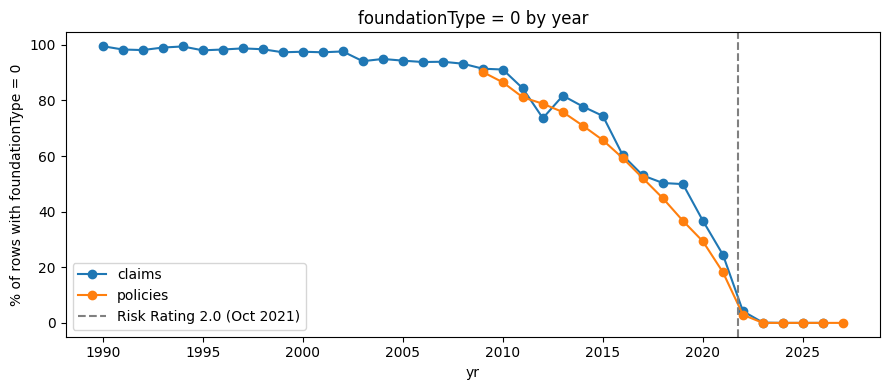

In [29]:
# Step 2.4.6b Share of code 0 by year: policies (effective year) and claims (year of loss)
is_zero = "CASE WHEN TRIM(CAST(foundationType AS VARCHAR)) = '0' THEN 1 ELSE 0 END"
zero_by_year = con.sql(f"""
    SELECT 'policies' AS source, 
            YEAR(policyEffectiveDate) AS yr, 
            COUNT(*) AS n,
            ROUND(100.0 * AVG({is_zero}), 1) AS pct_zero
    FROM raw_policies GROUP BY 1, 2
    UNION ALL
    SELECT 'claims', 
            yearOfLoss, 
            COUNT(*), 
            ROUND(100.0 * AVG({is_zero}), 1)
    FROM raw_claims GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

pivot = zero_by_year.pivot(index="yr", columns="source", values="pct_zero")
ax = pivot.loc[pivot.index >= 1990].plot(marker="o", figsize=(9, 4))
ax.axvline(2021.75, color="grey", linestyle="--", label="Risk Rating 2.0 (Oct 2021)")
ax.set_ylabel("% of rows with foundationType = 0")
ax.set_title("foundationType = 0 by year")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "fig_foundation_zero_by_year.png", dpi=150)

pivot.tail(20)

`foundationType` = 0 is not a foundation type. Its share is about X% of policy terms before 2010 and Y% from 2010 onwards (2.4.6b), so the field was not collected before 2010. The rate method (2.4.6c) and the building pattern (2.4.6d) don’t explain it. 

**Treatment:** set to NULL and flag with dq_invalid_foundationType. The missing values come from the policy year, not chance, so notebook 04 must handle them by year rather than fill them in.

In [30]:
# Step 2.4.6c Share of code 0 by rating method
for view in ["raw_policies", "raw_claims"]:
    print(view)
    display(con.sql(f"""
        SELECT rateMethod, COUNT(*) AS n,
               ROUND(100.0 * AVG({is_zero}), 1) AS pct_zero
        FROM {view}
        GROUP BY 1 ORDER BY 2 DESC
    """).df())

raw_policies


,rateMethod,n,pct_zero
0,1,27927203,67.0
1,7,23214648,58.6
2,RE,16876860,0.0
3,B,2892067,43.5
4,R,1356374,35.7
5,2,1343142,52.2
6,Q,425036,68.1
7,W,302123,36.9
8,P,150531,76.4
9,G,88837,58.2


raw_claims


,rateMethod,n,pct_zero
0,1,1738392,100.0
1,RE,526829,0.0
2,7,254646,100.0
3,2,44951,100.0
4,B,43162,100.0
5,3,36581,100.0
6,None,33319,100.0
7,G,18526,89.7
8,R,9880,100.0
9,Q,5677,100.0


It seems that rating method is not a factor in the foundationtype given that the distribution is consistent.

In [31]:
# Step 2.4.6d Building pattern of each foundationType value (policies)
# If the 0 row looks like one specific code, 0 might be that type; if it looks like the average, 0 = unknown
building = con.sql("""
    SELECT TRIM(CAST(foundationType AS VARCHAR)) AS foundation,
           COUNT(*) AS n,
           ROUND(100.0 * AVG(CAST(TRY_CAST(elevatedBuildingIndicator AS BOOLEAN) AS INTEGER)), 1) AS pct_elevated
    FROM raw_policies
    GROUP BY 1 ORDER BY 1
""").df()
display(building)

# Basement / enclosure / crawlspace mix per foundation value (row %, see the dictionary for the codes)
mix = con.sql("""
    SELECT TRIM(CAST(foundationType AS VARCHAR)) AS foundation,
           CAST(basementEnclosureCrawlspaceType AS VARCHAR) AS basement_type,
           COUNT(*) AS n
    FROM raw_policies
    GROUP BY 1, 2
""").df()
print(policies_dict.loc[policies_dict["name"] == "basementEnclosureCrawlspaceType", "description"].iloc[0])
(mix.pivot_table(index="foundation", columns="basement_type", values="n", aggfunc="sum", fill_value=0)
    .pipe(lambda t: (100 * t.div(t.sum(axis=1), axis=0)).round(1)))

,foundation,n,pct_elevated
0,0,35462531,15.6
1,1,27073842,0.2
2,2,3427754,0.3
3,3,3453173,63.7
4,4,2528881,88.7
5,5,1476223,86.2
6,6,1317057,89.0


Basement is defined for purposes of the NFIP as any level or story which has its floor subgrade on all sides.  Basement structure value are as follow:                                                                                                                       
0  - None;    
1 - Finished Basement/Enclosure;
2 - Unfinished Basement/Enclosure;
3 - Crawlspace;
4 - Subgrade Crawlspace;


basement_type,0,1,2,4
foundation,,,,
0,43.9,20.4,30.6,5.1
1,99.9,0.1,0.1,0.0
2,0.5,47.0,52.4,0.1
3,52.6,0.4,2.3,44.7
4,99.4,0.1,0.3,0.1
5,38.9,14.3,46.6,0.2
6,79.8,6.2,13.8,0.2


##### 2.4.6e Check `policyTermIndicator`
The dictionary allows 1 (one year), 3 (three years) and 9 (other). The data also has 0, 2, 4, 5 and 6. Before deciding, check how long these policies actually last. If most `2` rows last about two years, `2` is a real code and should be added in Step 2.4.3.

**Treatment: pending.** For now these values are set to NULL in Section 3 with a `dq_invalid_policyTermIndicator` flag. Revisit after reading the table below.

In [32]:
# Step 2.4.6e Actual term length of each policyTermIndicator value
print(policies_dict.loc[policies_dict["name"] == "policyTermIndicator", "description"].iloc[0])

term_check = con.sql("""
    SELECT policyTermIndicator,
           ROUND(date_diff('day', policyEffectiveDate, policyTerminationDate) / 365.25, 1) AS term_years,
           COUNT(*) AS n
    FROM raw_policies
    GROUP BY 1, 2
""").df()

# Top 5 term lengths for each indicator value, with their share
term_check["pct_of_value"] = (100 * term_check["n"]
                              / term_check.groupby("policyTermIndicator")["n"].transform("sum")).round(1)
(term_check.sort_values(["policyTermIndicator", "n"], ascending=[True, False])
           .groupby("policyTermIndicator").head(5))

Indicates length of time for which policy is in effect.  As set forth in the Flood Insurance Application form, coverage is provided for an initial policy term of 1 or 3 years and for successive terms of 1 or 3 years, provided the premium for each succeeding term is paid in full and received by the NFIP prior to the expiration of the then current term.  Other terms between 1 and 3 years may be written to coincide with the term of other homeowner's insurance policies.  Preferred Risk Policies are allowed only 1-year terms.  Three-year terms are allowed only for Group Flood policies: 
1 - 1 year;
3 - 3 years (only for policies effective prior to May 1, 1999);
9 - Other (between 1 and 3 years);


,policyTermIndicator,term_years,n,pct_of_value
65,0,1.0,14,100.0
43,1,1.0,74649834,100.0
23,1,0.0,596,0.0
19,1,1.6,356,0.0
40,1,1.8,106,0.0
9,1,1.9,93,0.0
3,2,2.9,8165,43.0
39,2,2.8,3470,18.3
29,2,2.6,2470,13.0
51,2,2.7,2445,12.9


In [33]:
# Step 2.4.6f When do the unexpected values appear? (a code used only in some years points to a system change)
con.sql("""
    SELECT YEAR(policyEffectiveDate) AS yr, policyTermIndicator, COUNT(*) AS n
    FROM raw_policies
    WHERE TRY_CAST(policyTermIndicator AS INTEGER) NOT IN (1, 3, 9)
    GROUP BY 1, 2
    ORDER BY 2, 1
""").df().pivot(index="yr", columns="policyTermIndicator", values="n").fillna(0).astype(int)

policyTermIndicator,0,2,4,5,6
yr,,,,,
2017,1,0,0,0,0
2018,1,0,0,0,0
2021,2,258,0,1,0
2022,10,773,5,4,6
2023,0,2669,0,0,0
2024,0,3817,0,0,0
2025,0,11165,0,0,0
2026,0,317,0,0,0


policyTermIndicator allows 1 (1 year), 3 (3 years) and 9 (other). Codes 0, 4, 5 and 6 (30 rows) all last about 1 year. Code 2 (18,999 rows) appears only from 2021, and 89% of its terms last 2.5–3.0 years, so it is not a 2-year term and its meaning is undocumented. About 73% of code-3 terms last about 3 years; the rest last 1.25–2.75 years, and cancellation doesn’t explain it (under 10% cancelled in every bin). Treatment: undocumented codes are set to NULL and flagged. Term length is taken from the dates, not the indicator, and multi-year terms (0.12% of rows) are split into 1-year periods in notebook 03.

#### 2.4.7 Treatment of the invalid values
Every value listed below is set to NULL in the clean views (Section 3), and a `dq_invalid_<column>` flag remembers which rows were changed. 

In [34]:
# Step 2.4.7 The invalid values that Section 3 will set to NULL (+ dq_invalid_<column> flag)
invalid.groupby(["table", "column"]).agg(values=("value", lambda v: sorted(v)), rows=("n", "sum"))

values      rows
table        column                                                           
raw_claims   buildingDescriptionCode                            [21]         2
             causeOfDamage                           [5, 6, @, N, Z]        25
             disasterAssistanceCoverageRequired                  [3]      1103
             foundationType                                      [0]   2197183
             ratedFloodZone                                 [AA, AS]        11
raw_policies buildingDescriptionCode                    [21, 32, 34]        19
             disasterAssistanceCoverageRequiredCode              [3]       515
             floodZoneCurrent                                   [AA]         5
             foundationType                                      [0]  35462531
             policyTermIndicator                     [0, 2, 4, 5, 6]     19029

In [35]:
# Step 2.4.8 Save
allowed_summary.to_csv(REPORTS / "dq_allowed_values_check.csv")          # keeps the table/column/kind index
invalid.to_csv(REPORTS / "dq_invalid_values_detail.csv", index=False)
review.to_csv(REPORTS / "dq_invalid_values_review.csv", index=False)

#### 2.5 Count the nulls of each columns
Flag constant or near-constant columns and columns that are 100% null.

In [36]:
# Step 2.5.1 Null, placeholder and constant-column profile
nulls = pd.concat([null_profile(con, v) for v in
                   ["raw_policies", "raw_claims", "raw_community", "raw_disasters"]],
                  ignore_index=True)

In [37]:
# Step 2.5.2 Suggested treatment
nulls["suggestion"] = nulls.apply(suggest_null_treatment, axis=1)
display(nulls["suggestion"].value_counts())
display(nulls[nulls["suggestion"].str.startswith(("drop", "review"))]
        .sort_values(["suggestion", "true_missing_pct"], ascending=[True, False]))

suggestion
keep                             69
keep; handle missing in 05       66
review: mostly missing - why?    47
review: near-constant            24
placeholders -> NULL              7
drop column: constant             4
drop column: all missing          1
Name: count, dtype: int64

,table,column,type,total,null_n,null_pct,placeholder_n,placeholder_pct,true_missing_pct,hidden_pct,distinct,top_value,top_value_pct,suggestion
74,raw_policies,reportedCity,VARCHAR,74739461,0,0.0,74739461,100.0,100.0,100.0,1,NA,100.000000,drop column: all missing
1,raw_policies,asOfDate,TIMESTAMP WITH TIME ZONE,74739461,0,0.0,0,0.0,0.0,0.0,1,2026-09-08 08:00:00+08,100.000000,drop column: constant
88,raw_claims,asOfDate,TIMESTAMP WITH TIME ZONE,2725989,0,0.0,0,0.0,0.0,0.0,1,2026-09-08 08:00:00+08,100.000000,drop column: constant
152,raw_claims,reportedCity,VARCHAR,2725989,0,0.0,0,0.0,0.0,0.0,1,Currently Unavailable,100.000000,drop column: constant
216,raw_disasters,lastRefresh,TIMESTAMP,70599,0,0.0,0,0.0,0.0,0.0,1,2026-11-06 12:27:53.589,100.000000,drop column: constant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,raw_claims,smallBusinessIndicatorBuilding,BOOLEAN,2725989,0,0.0,0,0.0,0.0,0.0,2,false,99.366395,review: near-constant
133,raw_claims,floodproofedIndicator,BOOLEAN,2725989,0,0.0,0,0.0,0.0,0.0,2,false,99.986390,review: near-constant
146,raw_claims,stateOwnedIndicator,BOOLEAN,2725989,0,0.0,0,0.0,0.0,0.0,2,false,99.925055,review: near-constant
179,raw_community,tribal,BOOLEAN,25133,0,0.0,0,0.0,0.0,0.0,2,false,99.789122,review: near-constant


About 5 columns (reportedCity, asOfDate, lastRefresh) would be dropped due to 100% null or 100% one value. 

In [38]:
# Step 2.5.3 Save (the treatments are applied and logged in Section 3)
nulls.to_csv(REPORTS / "dq_missing_raw.csv", index=False)

#### 2.6 Check the validity of the dates
Check plausibility: negative premiums or coverage, coverage above NFIP limits, termination before effective date, construction dates in the future or before 1800, loss dates outside 1978 to today.

In [39]:
# Step 2.6a Plausibility rules for policies (each condition = a violation)
policy_rules = {
    "term_end_before_start":     "policyTerminationDate <= policyEffectiveDate",
    "term_longer_than_3y":       "date_diff('day', policyEffectiveDate, policyTerminationDate) > 3*366",
    "effective_in_future":       "policyEffectiveDate > asOfDate",
    "effective_before_1968":     "policyEffectiveDate < DATE '1968-01-01'",
    "nb_after_effective":        "originalNBDate > policyEffectiveDate",
    "nb_before_1968":            "originalNBDate < DATE '1968-01-01'",
    "construction_before_1800":  "originalConstructionDate < DATE '1800-01-01'",
    "construction_in_future":    "originalConstructionDate > asOfDate",
    "cancel_before_effective":   "cancellationDateOfFloodPolicy < policyEffectiveDate",
    "cancel_after_termination":  "cancellationDateOfFloodPolicy > policyTerminationDate",
    "negative_premium":          "totalInsurancePremiumOfThePolicy < 0",
    "negative_policy_cost":      "policyCost < 0",
    "negative_building_cov":     "totalBuildingInsuranceCoverage < 0",
    "negative_contents_cov":     "totalContentsInsuranceCoverage < 0",
    "building_cov_over_limit":   "totalBuildingInsuranceCoverage > 500000 AND COALESCE(policyCount,1) = 1",
    "contents_cov_over_limit":   "totalContentsInsuranceCoverage > 500000 AND COALESCE(policyCount,1) = 1",
    "policycount_zero_or_less":  "policyCount <= 0",
    "latitude_out_of_range":     "latitude NOT BETWEEN -15 AND 72",
    "longitude_out_of_range":    "longitude NOT BETWEEN -180 AND 146",
    "term_mismatch": """CASE TRY_CAST(policyTermIndicator AS INTEGER)
                                    WHEN 1 THEN date_diff('day', policyEffectiveDate, policyTerminationDate) NOT BETWEEN 360 AND 370
                                    WHEN 3 THEN date_diff('day', policyEffectiveDate, policyTerminationDate) NOT BETWEEN 1090 AND 1100
                                END""",
}
plaus_policies = run_rules(con, "raw_policies", policy_rules)
plaus_policies

,table,rule,condition,violations,violation_pct
0,raw_policies,term_end_before_start,policyTerminationDate <= policyEffectiveDate,560,0.000749
1,raw_policies,term_longer_than_3y,"date_diff('day', policyEffectiveDate, policyTerminationDate) > 3*366",43,0.000058
2,raw_policies,effective_in_future,policyEffectiveDate > asOfDate,215731,0.288644
3,raw_policies,effective_before_1968,policyEffectiveDate < DATE '1968-01-01',0,0.000000
4,raw_policies,nb_after_effective,originalNBDate > policyEffectiveDate,2130987,2.851221
5,raw_policies,nb_before_1968,originalNBDate < DATE '1968-01-01',2086,0.002791
6,raw_policies,construction_before_1800,originalConstructionDate < DATE '1800-01-01',77056,0.103099
7,raw_policies,construction_in_future,originalConstructionDate > asOfDate,25,0.000033
8,raw_policies,cancel_before_effective,cancellationDateOfFloodPolicy < policyEffectiveDate,37820,0.050602
9,raw_policies,cancel_after_termination,cancellationDateOfFloodPolicy > policyTerminationDate,9,0.000012


About <1% have violations which could largely be ignored due to materiality. 

In [40]:
# Step 2.6b Plausibility rules for claims (each condition = a violation)
claim_rules = {
    "loss_before_1978":          "dateOfLoss < DATE '1978-01-01'",
    "loss_in_future":            "dateOfLoss > asOfDate",
    "nb_after_loss":             "originalNBDate > dateOfLoss",
    "construction_after_loss":   "originalConstructionDate > dateOfLoss",
    "negative_building_paid":    "amountPaidOnBuildingClaim < 0",
    "negative_contents_paid":    "amountPaidOnContentsClaim < 0",
    "building_paid_over_cov":    "amountPaidOnBuildingClaim > totalBuildingInsuranceCoverage * 1.01",
    "contents_paid_over_cov":    "amountPaidOnContentsClaim > totalContentsInsuranceCoverage * 1.01",
    "year_mismatch":             "yearOfLoss <> YEAR(dateOfLoss)",
}
plaus_claims = run_rules(con, "raw_claims", claim_rules)
plaus_claims

,table,rule,condition,violations,violation_pct
0,raw_claims,loss_before_1978,dateOfLoss < DATE '1978-01-01',0,0.000000
1,raw_claims,loss_in_future,dateOfLoss > asOfDate,0,0.000000
2,raw_claims,nb_after_loss,originalNBDate > dateOfLoss,38519,1.413028
3,raw_claims,construction_after_loss,originalConstructionDate > dateOfLoss,12875,0.472306
4,raw_claims,negative_building_paid,amountPaidOnBuildingClaim < 0,84,0.003081
5,raw_claims,negative_contents_paid,amountPaidOnContentsClaim < 0,47,0.001724
6,raw_claims,building_paid_over_cov,amountPaidOnBuildingClaim > totalBuildingInsuranceCoverage * 1.01,11042,0.405064
7,raw_claims,contents_paid_over_cov,amountPaidOnContentsClaim > totalContentsInsuranceCoverage * 1.01,31878,1.169410
8,raw_claims,year_mismatch,yearOfLoss <> YEAR(dateOfLoss),0,0.000000


In [41]:
# Step 2.6c Plausibility rules for disasters (each condition = a violation)
disaster_rules = {
    "incident_end_before_begin": "incidentEndDate < incidentBeginDate",
    "declared_before_incident":  "declarationDate < incidentBeginDate - INTERVAL 30 DAY",
    "declared_before_1953":      "declarationDate < DATE '1953-01-01'",
}
plaus_disasters = run_rules(con, "raw_disasters", disaster_rules)
plaus_disasters

,table,rule,condition,violations,violation_pct
0,raw_disasters,incident_end_before_begin,incidentEndDate < incidentBeginDate,2,0.002833
1,raw_disasters,declared_before_incident,declarationDate < incidentBeginDate - INTERVAL 30 DAY,11,0.015581
2,raw_disasters,declared_before_1953,declarationDate < DATE '1953-01-01',0,0.000000


In [42]:
# Step 2.6d Review and save
plausibility = pd.concat([plaus_policies, plaus_claims, plaus_disasters], ignore_index=True)
plausibility.to_csv(REPORTS / "dq_plausibility_raw.csv", index=False)
plausibility.sort_values("violation_pct", ascending=False)

,table,rule,condition,violations,violation_pct
4,raw_policies,nb_after_effective,originalNBDate > policyEffectiveDate,2130987,2.851221
22,raw_claims,nb_after_loss,originalNBDate > dateOfLoss,38519,1.413028
27,raw_claims,contents_paid_over_cov,amountPaidOnContentsClaim > totalContentsInsuranceCoverage * 1.01,31878,1.169410
23,raw_claims,construction_after_loss,originalConstructionDate > dateOfLoss,12875,0.472306
26,raw_claims,building_paid_over_cov,amountPaidOnBuildingClaim > totalBuildingInsuranceCoverage * 1.01,11042,0.405064
2,raw_policies,effective_in_future,policyEffectiveDate > asOfDate,215731,0.288644
14,raw_policies,building_cov_over_limit,"totalBuildingInsuranceCoverage > 500000 AND COALESCE(policyCount,1) = 1",148442,0.198613
6,raw_policies,construction_before_1800,originalConstructionDate < DATE '1800-01-01',77056,0.103099
19,raw_policies,term_mismatch,"CASE TRY_CAST(policyTermIndicator AS INTEGER)\n WHEN 1 THEN date_diff('day', poli...",57670,0.077161
8,raw_policies,cancel_before_effective,cancellationDateOfFloodPolicy < policyEffectiveDate,37820,0.050602


#### 2.7 Check for duplicates in the primary keys
Check that `id` is unique in each FEMA table. Count fully duplicated rows, meaning rows identical in every column except `id` (the same record published twice). Report the counts per table and log them. Don't remove anything yet.

In [43]:
# Step 2.7.1 Primary key uniqueness (the primary key comes from the dictionary)
dicts = {"raw_policies": policies_dict, "raw_claims": claim_dict,
         "raw_disasters": disaster_dict, "raw_community": community_dict}

pk_rows = []
for view, dct in dicts.items():
    pk = dct.loc[dct["primaryKey"] == True, "name"].tolist() or ["id"]
    pk_cols = ", ".join(f'"{c}"' for c in pk)
    total, distinct, null_pk = con.execute(f"""
        SELECT COUNT(*),
               COUNT(DISTINCT ({pk_cols})),
               COUNT(*) FILTER (WHERE {" OR ".join(f'"{c}" IS NULL' for c in pk)})
        FROM {view}
    """).fetchall()[0]
    pk_rows.append({"table": view, "primary_key": ", ".join(pk), "rows": total,
                    "duplicate_keys": total - distinct, "null_keys": null_pk})

pk_check = pd.DataFrame(pk_rows)
pk_check

,table,primary_key,rows,duplicate_keys,null_keys
0,raw_policies,id,74739461,0,0
1,raw_claims,id,2725989,0,0
2,raw_disasters,"disasterNumber, placeCode",70599,0,0
3,raw_community,communityIdNumber,25133,0,0


No duplicates have been noted in the primary keys. 

In [44]:
# Step 2.7.2 Rows identical in every column except the key and metadata columns.
# DUP_EXCLUDE is used again for de-duplication (2.7.3) and for the re-check (4.1),
# so the rows removed are exactly the rows counted here.
DUP_EXCLUDE = {r["table"]: {c.strip() for c in r["primary_key"].split(",")} | METADATA_COLUMNS
               for _, r in pk_check.iterrows()}

dup_rows = []
for _, r in pk_check.iterrows():
    extra_rows, groups = count_duplicates(con, r["table"], DUP_EXCLUDE[r["table"]])
    dup_rows.append({"table": r["table"], "duplicate_rows": extra_rows, "duplicate_groups": groups,
                     "duplicate_pct": 100 * extra_rows / r["rows"]})

duplicates = pd.DataFrame(dup_rows)
duplicates

,table,duplicate_rows,duplicate_groups,duplicate_pct
0,raw_policies,719387,293917,0.962526
1,raw_claims,11382,5382,0.417537
2,raw_disasters,13,13,0.018414
3,raw_community,0,0,0.000000


In [45]:
# Step 2.7.3 Look at a few duplicate groups before removing anything
for view in ["raw_disasters", "raw_claims"]:
    print(view)
    display(duplicate_examples(con, view, DUP_EXCLUDE[view], n_groups=2))

raw_disasters


,0,1,2,3
group,1,1,2,2
id,63b7bb3c-c0ed-4685-82fb-a6b7b4946e59,d32bdff4-9978-468a-81bd-15064abca2f1,e2ba4689-7656-49de-a411-4d9bc764fbcd,96a98aba-ce2c-4576-8e37-117662f0d7af
disasterNumber,3460,3460,3460,3460
state,NM,NM,NM,NM
femaDeclarationString,EM-3460-NM,EM-3460-NM,EM-3460-NM,EM-3460-NM
declarationType,EM,EM,EM,EM
declarationDate,2020-03-13 00:00:00,2020-03-13 00:00:00,2020-03-13 00:00:00,2020-03-13 00:00:00
fyDeclared,2020,2020,2020,2020
incidentType,Biological,Biological,Biological,Biological
declarationTitle,COVID-19,COVID-19,COVID-19,COVID-19


raw_claims


,0,1,2,3,4,5,6
group,1,1,1,1,1,2,2
agricultureStructureIndicator,False,False,False,False,False,False,False
asOfDate,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00,2026-09-08 08:00:00+08:00
basementEnclosureCrawlspaceType,<NA>,<NA>,<NA>,<NA>,<NA>,0,0
policyCount,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...
totalBldgClaimPmtRecovery,NaN,NaN,NaN,NaN,NaN,NaN,NaN
totalContentsClaimPmtRecovery,NaN,NaN,NaN,NaN,NaN,NaN,NaN
totalIccClaimPmtRecovery,NaN,NaN,NaN,NaN,NaN,NaN,NaN
totalSubrogationRecovery,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
# Step 2.7.4 Disasters and claims: remove the extra copies. Policies: keep everything, flag identical groups.
con.execute(f"CREATE OR REPLACE VIEW dedup_disasters AS {dedup_sql(con, 'raw_disasters', DUP_EXCLUDE['raw_disasters'])}")
con.execute(f"CREATE OR REPLACE VIEW dedup_claims    AS {dedup_sql(con, 'raw_claims', DUP_EXCLUDE['raw_claims'])}")
con.execute(f"CREATE OR REPLACE VIEW dedup_policies  AS "
            f"{dedup_sql(con, 'raw_policies', DUP_EXCLUDE['raw_policies'], mode='flag')}")

# Rows removed should equal the duplicate rows counted in 2.7.2
expected = duplicates.set_index("table")["duplicate_rows"]
for raw, dd in [("raw_disasters", "dedup_disasters"), ("raw_claims", "dedup_claims")]:
    before, after = scalar(con, f"SELECT COUNT(*) FROM {raw}"), scalar(con, f"SELECT COUNT(*) FROM {dd}")
    print(f"{raw}: {before:,} -> {after:,}  removed {before - after:,} (expected {expected[raw]:,})")

con.sql("""SELECT dq_identical_group_size, COUNT(*) AS rows
           FROM dedup_policies GROUP BY 1 ORDER BY 1""").df()

raw_disasters: 70,599 -> 70,586  removed 13 (expected 13)
raw_claims: 2,725,989 -> 2,714,607  removed 11,382 (expected 11,382)


,dq_identical_group_size,rows
0,1,73726157
1,2,366814
2,3,135120
3,4,88868
4,5,59695
...,...,...
135,227,227
136,228,456
137,231,1155
138,235,235


In [47]:
# Step 2.7.5 Log
dup = duplicates.set_index("table")["duplicate_rows"]
log.add("raw_disasters", "ALL", "remove exact duplicates (keep lowest id)",
        "same declaration and county published twice; check the examples in 2.7.3", dup["raw_disasters"])
log.add("raw_claims", "ALL", "remove exact duplicates (keep lowest id)",
        "identical claim records under different ids", dup["raw_claims"])
log.add("raw_policies", "ALL", "flag dq_identical_group_size (rows kept)",
        "identical after redaction; likely separate units, decided in notebook 04", dup["raw_policies"])

#### 2.8 Check the validity of censusGeoid and zip codes
- **Format:** `censusGeoid` should be 11 digits, zip codes 5 digits, and county codes 5 digits.
- **Consistency:** the state from the first two digits of `censusGeoid` should match `propertyState`.
- **Integrity:** count claims whose `censusGeoid`/zip never appears in policies (they can't be linked), and disaster counties that never appear in policies. Count community IDs in policies with no match in the Community Status Book.

In [48]:
# Step 2.8a Format checks: each condition = a violation
geo_format_rules = {
    "raw_policies": {
        "geoid_not_11_digits": "NOT regexp_matches(CAST(censusGeoid AS VARCHAR), '^\\d{11}$')",
        "zip_not_5_digits":    "NOT regexp_matches(CAST(reportedZipCode AS VARCHAR), '^\\d{5}$')",
        "state_not_2_letters": "NOT regexp_matches(propertyState, '^[A-Z]{2}$')",
    },
    "raw_claims": {
        "geoid_not_11_digits":  "NOT regexp_matches(CAST(censusGeoid AS VARCHAR), '^\\d{11}$')",
        "zip_not_5_digits":     "NOT regexp_matches(CAST(reportedZipCode AS VARCHAR), '^\\d{5}$')",
        "county_not_5_digits":  "NOT regexp_matches(CAST(countyCode AS VARCHAR), '^\\d{5}$')",
    },
    "raw_disasters": {
        "state_fips_not_2":  "NOT regexp_matches(CAST(fipsStateCode AS VARCHAR), '^\\d{2}$')",
        "county_fips_not_3": "NOT regexp_matches(CAST(fipsCountyCode AS VARCHAR), '^\\d{3}$')",
    },
}

geo_checks = pd.concat([run_rules(con, view, rules) for view, rules in geo_format_rules.items()],
                       ignore_index=True)
geo_checks

,table,rule,condition,violations,violation_pct
0,raw_policies,geoid_not_11_digits,"NOT regexp_matches(CAST(censusGeoid AS VARCHAR), '^\d{11}$')",74428755,99.584281
1,raw_policies,zip_not_5_digits,"NOT regexp_matches(CAST(reportedZipCode AS VARCHAR), '^\d{5}$')",53843,0.072041
2,raw_policies,state_not_2_letters,"NOT regexp_matches(propertyState, '^[A-Z]{2}$')",9,0.000012
3,raw_claims,geoid_not_11_digits,"NOT regexp_matches(CAST(censusGeoid AS VARCHAR), '^\d{11}$')",2588848,94.969129
4,raw_claims,zip_not_5_digits,"NOT regexp_matches(CAST(reportedZipCode AS VARCHAR), '^\d{5}$')",56130,2.059069
5,raw_claims,county_not_5_digits,"NOT regexp_matches(CAST(countyCode AS VARCHAR), '^\d{5}$')",0,0.000000
6,raw_disasters,state_fips_not_2,"NOT regexp_matches(CAST(fipsStateCode AS VARCHAR), '^\d{2}$')",0,0.000000
7,raw_disasters,county_fips_not_3,"NOT regexp_matches(CAST(fipsCountyCode AS VARCHAR), '^\d{3}$')",0,0.000000


In [49]:
# Step 2.8b Zip code lengths: a length of 4 means a lost leading zero (fixed with LPAD in Section 3)
con.sql("""
    SELECT LENGTH(CAST(reportedZipCode AS VARCHAR)) AS len, COUNT(*) AS n,
           ANY_VALUE(reportedZipCode) AS example
    FROM raw_policies GROUP BY 1 ORDER BY 2 DESC
""").df()

,len,n,example
0,5,74685618,70358
1,10,48192,70005-2806
2,0,4439,
3,4,1047,2532
4,3,108,820
5,6,41,27936-
6,9,13,704716711
7,7,3,70119-8


In [50]:
# Step 2.8c State from censusGeoid vs propertyState
register_state_fips(con)          # temp table state_fips(fips, state); see src/geo.py

state_mismatch = con.sql(f"""
    SELECT p.propertyState, s.state AS state_from_geoid, COUNT(*) AS n
    FROM raw_policies p
    LEFT JOIN state_fips s ON LEFT({padded('censusGeoid', 11)}, 2) = s.fips
    WHERE p.censusGeoid IS NOT NULL
      AND (s.state IS NULL OR s.state <> p.propertyState)
    GROUP BY 1, 2 ORDER BY 3 DESC
""").df()
state_mismatch.head(20)

,propertyState,state_from_geoid,n
0,MO,IL,95
1,TN,GA,93
2,TX,NM,90
3,AR,MS,81
4,DE,MD,69
5,ME,KS,64
6,NC,SC,62
7,WV,VA,51
8,LA,MS,47
9,LA,TX,46


In [51]:
# Step 2.8d Codes with no match in the table they must join to.
# NOT EXISTS is used instead of NOT IN: with NOT IN, a single NULL in the other table makes every row "not unmatched".
acs_geoids = pd.DataFrame({"geoid": (acs["state"].astype(str).str.zfill(2)
                                     + acs["county"].astype(str).str.zfill(3)
                                     + acs["tract"].astype(str).str.zfill(6))})
con.register("acs_geoids", acs_geoids)     # ACS is in pandas; register its 11-digit tract IDs for DuckDB

integrity_rules = {
    "claim_geoid_not_in_policies": """
        SELECT COUNT(*) FROM raw_claims c
        WHERE c.censusGeoid IS NOT NULL
          AND NOT EXISTS (SELECT 1 FROM raw_policies p WHERE p.censusGeoid = c.censusGeoid)""",
    "claim_zip_not_in_policies": """
        SELECT COUNT(*) FROM raw_claims c
        WHERE c.reportedZipCode IS NOT NULL
          AND NOT EXISTS (SELECT 1 FROM raw_policies p WHERE p.reportedZipCode = c.reportedZipCode)""",
    "policy_tracts_not_in_acs": f"""
        SELECT COUNT(DISTINCT censusGeoid) FROM raw_policies p
        WHERE p.censusGeoid IS NOT NULL
          AND NOT EXISTS (SELECT 1 FROM acs_geoids a WHERE a.geoid = {padded('censusGeoid', 11)})""",
    "policy_community_not_in_csb": f"""
        SELECT COUNT(*) FROM raw_policies p
        WHERE p.nfipCommunityNumberCurrent IS NOT NULL
          AND NOT EXISTS (SELECT 1 FROM raw_community c
                          WHERE {community_id6('communityIdNumber')} = {community_id6('nfipCommunityNumberCurrent')})""",
}

integrity = pd.DataFrame([{"check": k, "count": scalar(con, q)} for k, q in integrity_rules.items()])
integrity

,check,count
0,claim_geoid_not_in_policies,5373
1,claim_zip_not_in_policies,7155
2,policy_tracts_not_in_acs,41236
3,policy_community_not_in_csb,3963


In [52]:
# Step 2.8e Save (LPAD fixes and geo flags are applied and logged in Section 3)
geo_checks.to_csv(REPORTS / "dq_geo_format_raw.csv", index=False)
state_mismatch.to_csv(REPORTS / "dq_geo_state_mismatch_raw.csv", index=False)
integrity.to_csv(REPORTS / "dq_geo_integrity_raw.csv", index=False)

#### 2.9 Export the data-quality audit
Combine 2.1–2.8 into one `dq_audit_raw` table with one row per table and column: dtype, % null, % placeholder, % true missing, % invalid code, % implausible, top value %, and notes. Add a summary per table (rows, duplicates, unlinked rows). Export to `reports/`. This is our evidence that the data is messy.

In [53]:
# Step 2.9a One row per table and column
base = pd.concat([s.assign(table=view) for view, s in summaries.items()], ignore_index=True)
base = base.rename(columns={"column_name": "column", "column_type": "dtype"})[
    ["table", "column", "dtype", "count", "approx_unique", "min", "max"]]

allowed = (allowed_summary.reset_index()            # the 2.4 result
           [["table", "column", "kind", "invalid", "invalid_pct", "zero_padding_only"]]
           .rename(columns={"kind": "code_kind", "invalid": "invalid_n"}))

dq_audit_raw = (base
    .merge(nulls[["table", "column", "null_n", "placeholder_n", "true_missing_pct", "hidden_pct",
                  "top_value", "top_value_pct"]], on=["table", "column"], how="left")
    .merge(allowed, on=["table", "column"], how="left"))

# Plain-language flags, so the table is easy to read
def issues(r):
    found = []
    if r["true_missing_pct"] >= 100:            found.append("100% missing")
    elif r["true_missing_pct"] >= 50:           found.append("mostly missing (>50%)")
    if r["placeholder_n"] > 0:                  found.append("hidden missing (placeholders)")
    if r["invalid_n"] > 0:                      found.append("invalid codes")
    if r["top_value_pct"] >= 100:               found.append("one value only")
    elif r["top_value_pct"] >= 99:              found.append("near-constant (>=99%)")
    return "; ".join(found)

dq_audit_raw["issues"] = dq_audit_raw.apply(issues, axis=1)
dq_audit_raw.sort_values(["table", "true_missing_pct"], ascending=[True, False])

,table,column,dtype,count,approx_unique,min,max,null_n,placeholder_n,true_missing_pct,hidden_pct,top_value,top_value_pct,code_kind,invalid_n,invalid_pct,zero_padding_only,issues
160,raw_claims,mostRecentRecoveryDate,DATE,2725989,6079,1978-10-11,2026-09-02,2689206,0,98.65,0.0,2016-01-09,1.979175,NaN,NaN,NaN,NaN,mostly missing (>50%)
165,raw_claims,totalSalvageRecovery,"DECIMAL(12,2)",2725989,4684,-507.00,244887.62,2689206,0,98.65,0.0,0.00,75.317402,NaN,NaN,NaN,NaN,mostly missing (>50%)
166,raw_claims,totalBldgClaimPmtRecovery,"DECIMAL(12,2)",2725989,6479,-20000.00,1000000.00,2689206,0,98.65,0.0,0.00,73.126172,NaN,NaN,NaN,NaN,mostly missing (>50%)
167,raw_claims,totalContentsClaimPmtRecovery,"DECIMAL(12,2)",2725989,2690,-19040.00,250000.00,2689206,0,98.65,0.0,0.00,52.108311,NaN,NaN,NaN,NaN,mostly missing (>50%)
168,raw_claims,totalIccClaimPmtRecovery,"DECIMAL(12,2)",2725989,241,-15000.00,30000.00,2689206,0,98.65,0.0,0.00,98.860887,NaN,NaN,NaN,NaN,mostly missing (>50%)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,raw_policies,buildingOnFederalLand,BOOLEAN,74739461,2,false,true,0,0,0.00,0.0,false,99.976296,NaN,NaN,NaN,NaN,near-constant (>=99%)
81,raw_policies,seasonallyOccupied,BOOLEAN,74739461,2,false,true,0,0,0.00,0.0,false,99.676785,NaN,NaN,NaN,NaN,near-constant (>=99%)
84,raw_policies,foundationType,VARCHAR,74739461,7,0,6,0,0,0.00,0.0,0,47.448203,codes,35462531.0,47.448,0.0,invalid codes
85,raw_policies,preFIRMConstructionIndicator,BOOLEAN,74739461,2,false,true,0,0,0.00,0.0,false,86.917353,NaN,NaN,NaN,NaN,


In [54]:
# Step 2.9b One row per table
plaus_by_table = (plausibility.groupby("table")["violations"].sum()
                  .rename("plausibility_violations").reset_index())
geo_by_table = (geo_checks.groupby("table")["violations"].sum()
                .rename("geo_format_violations").reset_index())

dq_table_summary = (pk_check.merge(duplicates, on="table")
    .merge(plaus_by_table, on="table", how="left")
    .merge(geo_by_table, on="table", how="left")
    .merge(dq_audit_raw.groupby("table").agg(
              columns=("column", "count"),
              columns_with_issues=("issues", lambda s: (s != "").sum()),
              avg_true_missing_pct=("true_missing_pct", "mean")).reset_index(),
           on="table", how="left")
    .fillna({"plausibility_violations": 0, "geo_format_violations": 0}))

dq_table_summary

,table,primary_key,rows,duplicate_keys,null_keys,duplicate_rows,duplicate_groups,duplicate_pct,plausibility_violations,geo_format_violations,columns,columns_with_issues,avg_true_missing_pct
0,raw_policies,id,74739461,0,0,719387,293917,0.962526,2671283.0,74482607.0,87,40,18.137241
1,raw_claims,id,2725989,0,0,11382,5382,0.417537,94445.0,2644978.0,84,39,28.915833
2,raw_disasters,"disasterNumber, placeCode",70599,0,0,13,13,0.018414,13.0,0.0,29,4,5.720000
3,raw_community,communityIdNumber,25133,0,0,0,0,0.000000,0.0,0.0,18,7,32.921667


In [55]:
# Step 2.9c Top findings
top_missing = dq_audit_raw.nlargest(10, "true_missing_pct")[["table", "column", "true_missing_pct"]]
top_hidden  = dq_audit_raw.nlargest(10, "hidden_pct")[["table", "column", "hidden_pct"]]
top_invalid = dq_audit_raw.nlargest(10, "invalid_pct")[["table", "column", "invalid_pct"]]
top_plaus   = plausibility.nlargest(10, "violations")[["table", "rule", "violations", "violation_pct"]]

for title, df in [("Most missing", top_missing), ("Most hidden missing", top_hidden),
                  ("Most invalid codes", top_invalid), ("Most plausibility violations", top_plaus)]:
    print(title)
    display(df)

Most missing


,table,column,true_missing_pct
74,raw_policies,reportedCity,100.00
160,raw_claims,mostRecentRecoveryDate,98.65
165,raw_claims,totalSalvageRecovery,98.65
166,raw_claims,totalBldgClaimPmtRecovery,98.65
167,raw_claims,totalContentsClaimPmtRecovery,98.65
168,raw_claims,totalIccClaimPmtRecovery,98.65
169,raw_claims,totalSubrogationRecovery,98.65
131,raw_claims,floodCharacteristicsIndicator,98.54
4,raw_policies,cancellationDateOfFloodPolicy,95.78
39,raw_policies,cancellationVoidanceReasonCode,95.78


Most hidden missing


,table,column,hidden_pct
74,raw_policies,reportedCity,100.0000
153,raw_claims,reportedZipCode,2.0480
70,raw_policies,mapPanelSuffix,0.0086
75,raw_policies,reportedZipCode,0.0059
0,raw_policies,agricultureStructureIndicator,0.0000
1,raw_policies,asOfDate,0.0000
2,raw_policies,baseFloodElevation,0.0000
3,raw_policies,basementEnclosureCrawlspaceType,0.0000
4,raw_policies,cancellationDateOfFloodPolicy,0.0000
5,raw_policies,condominiumCoverageTypeCode,0.0000


Most invalid codes


,table,column,invalid_pct
158,raw_claims,foundationType,80.601
84,raw_policies,foundationType,47.448
128,raw_claims,disasterAssistanceCoverageRequired,0.040
30,raw_policies,policyTermIndicator,0.025
62,raw_policies,disasterAssistanceCoverageRequiredCode,0.001
122,raw_claims,causeOfDamage,0.001
0,raw_policies,agricultureStructureIndicator,0.000
3,raw_policies,basementEnclosureCrawlspaceType,0.000
5,raw_policies,condominiumCoverageTypeCode,0.000
6,raw_policies,construction,0.000


Most plausibility violations


,table,rule,violations,violation_pct
4,raw_policies,nb_after_effective,2130987,2.851221
2,raw_policies,effective_in_future,215731,0.288644
14,raw_policies,building_cov_over_limit,148442,0.198613
6,raw_policies,construction_before_1800,77056,0.103099
19,raw_policies,term_mismatch,57670,0.077161
22,raw_claims,nb_after_loss,38519,1.413028
8,raw_policies,cancel_before_effective,37820,0.050602
27,raw_claims,contents_paid_over_cov,31878,1.169410
23,raw_claims,construction_after_loss,12875,0.472306
26,raw_claims,building_paid_over_cov,11042,0.405064


In [56]:
# Step 2.9d Export
with pd.ExcelWriter(REPORTS / "dq_audit_raw.xlsx") as xw:
    dq_table_summary.to_excel(xw, sheet_name="table_summary", index=False)
    dq_audit_raw.to_excel(xw, sheet_name="column_audit", index=False)
    allowed_summary.reset_index().to_excel(xw, sheet_name="allowed_values", index=False)
    invalid.to_excel(xw, sheet_name="invalid_values", index=False)
    plausibility.to_excel(xw, sheet_name="plausibility", index=False)
    pk_check.merge(duplicates, on="table").to_excel(xw, sheet_name="duplicates", index=False)
    geo_checks.to_excel(xw, sheet_name="geo_format", index=False)
    state_mismatch.to_excel(xw, sheet_name="geo_state_mismatch", index=False)
    integrity.to_excel(xw, sheet_name="geo_integrity", index=False)

dq_audit_raw.to_csv(REPORTS / "dq_audit_raw.csv", index=False)

### Section 3. Cleaning Rules
Apply the rules decided from the audit in Section 2. Every rule is logged with `log_rule`. The raw files are never edited: each table gets a clean DuckDB view.

#### 3.0 Decision table
For each column, record the problem, the action (keep, recode, cast, set to NULL, flag, drop column or drop row) and the reason, based on the audit.

Principles:
- Flag rather than delete.
- Never impute here (imputation is fitted on training data only, in notebook 05).
- Keep target-only columns (cancellation fields, claim amounts) but mark them, so they are never used as features.

In [57]:
# Step 3.0a Draft decision table from the audit (suggestions only; review every row)
# draft_decision is documented in src/clean.py
decisions = dq_audit_raw[["table", "column", "dtype", "true_missing_pct", "null_n", "placeholder_n",
                          "invalid_n", "zero_padding_only", "top_value_pct", "issues"]].copy()
decisions[["action", "reason"]] = decisions.apply(lambda r: pd.Series(draft_decision(r)), axis=1)
decisions["role"] = ""          # feature / target_only / key / metadata / drop
decisions["null_meaning"] = ""  # what NULL means when it is not just "unknown"
decisions["decided_by"] = "draft"
decisions["action"].value_counts()

action
keep as is                                                             196
invalid code -> NULL + dq flag                                           8
placeholder -> NULL                                                      7
drop column                                                              5
invalid code -> NULL + dq flag; compare codes without leading zeros      2
Name: count, dtype: int64

In [58]:
# Step 3.0b Decisions made during the audit
manual_decisions = {
    ("raw_community", "classRating"): ("cast INTEGER; add in_crs; crs_class_filled = 10 when NULL",
                                       "None = not in CRS program (no discount)", "feature",
                                       "not in CRS"),
    ("raw_community", "currentlyEffectiveMapDate"): ("parse MM/DD/YY; legend codes -> flags",
                                                     "two-digit years + legend codes", "feature",
                                                     "NSFHA / N/A"),
    ("raw_community", "regularEmergencyProgramDate"): ("parse MM/DD/YY; E -> flag",
                                                       "two-digit years + legend codes", "feature",
                                                       "not participating in the NFIP"),
    ("raw_community", "sanctionDate"): ("parse MM/DD/YY; (S)/(W) -> flags; add ever_sanctioned",
                                        "suspension codes appended to dates", "label_cleaning",
                                        "never sanctioned"),
    ("raw_policies", "foundationType"): ("code 0 -> NULL + flag", "undocumented code in ~47% of rows",
                                         "feature", "not reported"),
    ("raw_claims", "foundationType"): ("code 0 -> NULL + flag", "undocumented code in ~81% of rows",
                                       "feature", "not reported"),
    ("raw_policies", "rateMethod"): ("keep RE as valid", "RE = RatingEngine (Risk Rating 2.0)",
                                     "feature", ""),
    ("raw_policies", "cancellationVoidanceReasonCode"): ("decode to category", "not every cancellation is a lapse",
                                                         "target_only", "not cancelled"),
    ("raw_policies", "cancellationDateOfFloodPolicy"): ("keep", "used only to build the target",
                                                        "target_only", "not cancelled"),
    ("raw_policies", "policyTermIndicator"): ("PENDING: 0, 2, 4, 5, 6 -> NULL + flag for now",
                                              "not in dictionary; term length checked in 2.4.6e",
                                              "feature", ""),
    ("raw_policies", "id"): ("keep", "record key, not a policy ID", "key", ""),
    ("raw_claims", "id"): ("keep", "record key", "key", ""),
    ("raw_policies", "reportedCity"): ("drop column", "constant 'NA'", "drop", ""),
    ("raw_claims", "numberOfFloorsInTheInsuredBuilding"): ("rename to numberOfFloorsInInsuredBuilding",
                                                           "match policies column for linkage", "key", ""),
}
for (t, c), (action, reason, role, null_meaning) in manual_decisions.items():
    m = (decisions["table"] == t) & (decisions["column"] == c)
    assert m.any(), f"{t}.{c} not found in the decision table"
    decisions.loc[m, ["action", "reason", "role", "null_meaning", "decided_by"]] = \
        [action, reason, role, null_meaning, "team"]

# Columns proposed for dropping: check that no key or target column is here before continuing
display(decisions.loc[decisions["action"].str.contains("drop column"), ["table", "column", "reason", "decided_by"]])
decisions[decisions["decided_by"] == "team"]

,table,column,reason,decided_by
1,raw_policies,asOfDate,constant: one value in every row,draft
74,raw_policies,reportedCity,constant 'NA',team
88,raw_claims,asOfDate,constant: one value in every row,draft
152,raw_claims,reportedCity,constant: one value in every row,draft
216,raw_disasters,lastRefresh,constant: one value in every row,draft


,table,column,dtype,true_missing_pct,null_n,placeholder_n,invalid_n,zero_padding_only,top_value_pct,issues,action,reason,role,null_meaning,decided_by
4,raw_policies,cancellationDateOfFloodPolicy,DATE,95.78,71586182,0,NaN,NaN,0.075953,mostly missing (>50%),keep,used only to build the target,target_only,not cancelled,team
30,raw_policies,policyTermIndicator,SMALLINT,0.00,0,0,19029.0,0.0,99.881839,invalid codes; near-constant (>=99%),"PENDING: 0, 2, 4, 5, 6 -> NULL + flag for now",not in dictionary; term length checked in 2.4.6e,feature,,team
33,raw_policies,rateMethod,VARCHAR,0.00,203,0,0.0,0.0,37.366176,,keep RE as valid,RE = RatingEngine (Risk Rating 2.0),feature,,team
39,raw_policies,cancellationVoidanceReasonCode,VARCHAR,95.78,71586182,0,0.0,0.0,48.386521,mostly missing (>50%),decode to category,not every cancellation is a lapse,target_only,not cancelled,team
74,raw_policies,reportedCity,VARCHAR,100.00,0,74739461,NaN,NaN,100.000000,100% missing; hidden missing (placeholders); one value only,drop column,constant 'NA',drop,,team
84,raw_policies,foundationType,VARCHAR,0.00,0,0,35462531.0,0.0,47.448203,invalid codes,code 0 -> NULL + flag,undocumented code in ~47% of rows,feature,not reported,team
86,raw_policies,id,BIGINT,0.00,0,0,NaN,NaN,0.000001,,keep,"record key, not a policy ID",key,,team
102,raw_claims,numberOfFloorsInTheInsuredBuilding,SMALLINT,0.63,17248,0,0.0,0.0,52.089698,,rename to numberOfFloorsInInsuredBuilding,match policies column for linkage,key,,team
158,raw_claims,foundationType,VARCHAR,0.00,0,0,2197183.0,0.0,80.601316,invalid codes,code 0 -> NULL + flag,undocumented code in ~81% of rows,feature,not reported,team
170,raw_claims,id,BIGINT,0.00,0,0,NaN,NaN,0.000037,,keep,record key,key,,team


In [59]:
con.sql("""
    WITH t AS (
        SELECT TRY_CAST(policyTermIndicator AS INTEGER) AS ind,
               date_diff('day', policyEffectiveDate, policyTerminationDate) / 365.25 AS yrs
        FROM raw_policies
    )
    SELECT ind,
           CASE WHEN yrs < 0.9 THEN '<0.9y' WHEN yrs <= 1.1 THEN '~1y'
                WHEN yrs < 2.9 THEN '1.1-2.9y' WHEN yrs <= 3.1 THEN '~3y'
                WHEN yrs <= 4.1 THEN '3.1-4.1y' ELSE '>4.1y' END AS term_bucket,
           COUNT(*) AS n,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY ind), 2) AS pct_of_ind
    FROM t GROUP BY 1, 2 ORDER BY 1, 2
""").df()

,ind,term_bucket,n,pct_of_ind
0,0,~1y,14,100.00
1,1,1.1-2.9y,684,0.00
2,1,<0.9y,619,0.00
3,1,~1y,74649845,100.00
4,2,1.1-2.9y,15411,81.11
5,2,~1y,16,0.08
6,2,~3y,3572,18.80
7,3,1.1-2.9y,37489,54.14
8,3,<0.9y,31,0.04
9,3,~1y,65,0.09


Allowed codes 1, 2, 3, 9 (2 added: 99.9% of its terms last more than 1.1 years, 2.4.6e). Codes 0, 4, 5 and 6 set to NULL; their dates show 1-year terms. The indicator is not used as a feature. Term length comes from the dates, and multi-year terms (0.12% of rows) are split into 1-year periods in notebook 03 (option B). Terms that don’t match their indicator are flagged with dq_term_mismatch.

In [60]:
con.sql("""
    WITH t AS (
        SELECT TRY_CAST(policyTermIndicator AS INTEGER) AS ind,
               date_diff('day', policyEffectiveDate, policyTerminationDate) / 365.25 AS yrs,
               cancellationDateOfFloodPolicy IS NOT NULL AS cancelled,
               year(policyEffectiveDate) AS eff_year
        FROM raw_policies
        WHERE TRY_CAST(policyTermIndicator AS INTEGER) IN (2, 3)
    )
    SELECT ind,
           ROUND(FLOOR(yrs * 4) / 4, 2) AS yrs_bin,      -- quarter-year bins
           COUNT(*) AS n,
           ROUND(100 * AVG(cancelled::INT), 1) AS pct_cancelled,
           MIN(eff_year) AS first_year,
           MAX(eff_year) AS last_year
    FROM t
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()

,ind,yrs_bin,n,pct_cancelled,first_year,last_year
0,2,0.75,16,0.0,2021,2022
1,2,1.75,364,0.5,2021,2026
2,2,2.00,349,1.1,2022,2026
3,2,2.25,1216,8.7,2021,2026
4,2,2.50,5383,15.2,2021,2026
5,2,2.75,11655,7.9,2021,2026
6,2,3.00,16,0.0,2021,2021
7,3,0.00,3,0.0,2018,2018
8,3,0.25,2,50.0,2011,2015
9,3,0.50,7,0.0,2010,2020


In [61]:
# Step 3.0c Save for team review
decisions.to_excel(DOCS / "cleaning_decisions.xlsx", index=False)

In [62]:
# Step 3.0d After the team edits docs/cleaning_decisions.xlsx, read it back (skip if nothing changed)
decisions = pd.read_excel(DOCS / "cleaning_decisions.xlsx")
decisions["action"].value_counts()

action
keep as is                                                             186
placeholder -> NULL                                                      7
drop column                                                              5
invalid code -> NULL + dq flag                                           5
keep                                                                     3
invalid code -> NULL + dq flag; compare codes without leading zeros      2
code 0 -> NULL + flag                                                    2
PENDING: 0, 2, 4, 5, 6 -> NULL + flag for now                            1
keep RE as valid                                                         1
decode to category                                                       1
rename to numberOfFloorsInInsuredBuilding                                1
parse MM/DD/YY; legend codes -> flags                                    1
parse MM/DD/YY; E -> flag                                                1
cast INTEGER; add 

#### 3.1 Clean policies (`clean_policies` view)
- Trim and uppercase text, turn placeholders into NULL, and set invalid codes to NULL.
- Keep codes such as zip, geoid and zones as text, with zero-padding fixed.
- Group flood zones (A, V, X/B/C, D, unknown) while keeping the original column too.
- Clean community names (remove `*` and extra spaces).
- Derive the state and county from `censusGeoid`, plus the effective year, term length and tenure in months.
- Add `dq_` flags: bad dates, negative amounts, invalid codes, geo mismatch, `policyCount` > 1.
- Decode cancellation codes into categories: lapse, sold, rewrite, duplicate, void, other.
- Drop constant and 100%-null columns.

In [63]:
# Step 3.1a One cleaned expression per column (make_select is documented in src/clean.py)
pol_cols, pol_drop = make_select(con, "dedup_policies", "raw_policies", decisions, coded)
print(f"keeping {len(pol_cols)} columns, dropping {sorted(pol_drop)}")

keeping 86 columns, dropping ['asOfDate', 'reportedCity']


In [64]:
# Step 3.1b Special rules and derived fields
special = f"""
    -- geography: restore leading zeros, derive state/county
    {padded('reportedZipCode', 5)}                     AS zip5,
    {padded('censusGeoid', 11)}                        AS geoid11,
    LEFT({padded('censusGeoid', 11)}, 2)               AS state_fips,
    LEFT({padded('censusGeoid', 11)}, 5)               AS county_fips,
    {community_id6('nfipCommunityNumberCurrent')}      AS community_id6,
    TRIM(REPLACE(nfipCommunityName, '*', ''))          AS community_name_clean,

    -- flood zone groups (original column kept too)
    CASE
        WHEN ratedFloodZone LIKE 'V%'                         THEN 'V'
        WHEN ratedFloodZone LIKE 'A%'                         THEN 'A'
        WHEN ratedFloodZone IN ('X', 'B', 'C')                THEN 'X'
        WHEN ratedFloodZone = 'D'                             THEN 'D'
        ELSE 'UNKNOWN' END                                       AS zone_group,

    -- dates and tenure
    CAST(policyEffectiveDate AS DATE)                            AS effective_date,
    YEAR(policyEffectiveDate)                                    AS eff_year,
    date_diff('day', policyEffectiveDate, policyTerminationDate) AS term_days,
    date_diff('month', originalNBDate, policyEffectiveDate)      AS tenure_months,

    -- cancellation category (target-only)
    CASE
        WHEN cancellationVoidanceReasonCode IS NULL                       THEN 'not_cancelled'
        WHEN cancellationVoidanceReasonCode IN ('05','28','30','52')      THEN 'lapse'
        WHEN cancellationVoidanceReasonCode IN ('01','02')                THEN 'sold_removed'
        WHEN cancellationVoidanceReasonCode IN ('03','22','24','25')      THEN 'rewrite'
        WHEN cancellationVoidanceReasonCode IN ('04','17','26')           THEN 'duplicate'
        WHEN cancellationVoidanceReasonCode IN ('60','70')                THEN 'void'
        ELSE 'other' END                                         AS cancel_category,

    -- data-quality flags
    COALESCE(policyCount, 1) > 1                                 AS dq_multi_unit,
    dq_identical_group_size > 1                                  AS dq_identical_row,
    LEFT({padded('censusGeoid', 11)}, 2) <> COALESCE(sf.fips, '') AS dq_geo_state_mismatch
"""

# dq_ flags: one per plausibility rule (2.6) and one per column with invalid codes (2.4)
pol_invalid_cols = invalid.loc[invalid["table"] == "raw_policies", "column"].unique()
pol_flags = rule_flags(policy_rules) + invalid_code_flags(coded, "raw_policies", pol_invalid_cols)
len(pol_flags)

25

In [65]:
# Step 3.1c The clean_policies view
con.execute(f"""
CREATE OR REPLACE VIEW clean_policies AS
SELECT
    {", ".join(pol_cols)},
    {special},
    {", ".join(pol_flags)}
FROM dedup_policies p
LEFT JOIN state_fips sf ON sf.state = p.propertyState
""")
con.sql("DESCRIBE clean_policies").df()

,column_name,column_type,null,key,default,extra
0,agricultureStructureIndicator,BOOLEAN,YES,None,None,None
1,baseFloodElevation,"DECIMAL(8,2)",YES,None,None,None
2,basementEnclosureCrawlspaceType,SMALLINT,YES,None,None,None
3,cancellationDateOfFloodPolicy,DATE,YES,None,None,None
4,condominiumCoverageTypeCode,VARCHAR,YES,None,None,None
...,...,...,...,...,...,...
121,dq_invalid_buildingDescriptionCode,BOOLEAN,YES,None,None,None
122,dq_invalid_disasterAssistanceCoverageRequiredCode,BOOLEAN,YES,None,None,None
123,dq_invalid_floodZoneCurrent,BOOLEAN,YES,None,None,None
124,dq_invalid_foundationType,BOOLEAN,YES,None,None,None


In [66]:
# Step 3.1d Before/after check on a 1% sample
display(con.sql("""
    SELECT
        COUNT(*)                                                   AS rows,
        COUNT(*) FILTER (WHERE foundationType IS NULL)             AS foundation_null,
        COUNT(*) FILTER (WHERE dq_invalid_foundationType)          AS foundation_flagged,
        COUNT(*) FILTER (WHERE policyTermIndicator IS NULL)        AS term_ind_null,
        COUNT(*) FILTER (WHERE zone_group = 'UNKNOWN')             AS zone_unknown,
        COUNT(*) FILTER (WHERE LENGTH(zip5) <> 5)                  AS bad_zip,
        COUNT(*) FILTER (WHERE dq_term_end_before_start)           AS bad_terms,
        COUNT(*) FILTER (WHERE dq_multi_unit)                      AS multi_unit
    FROM clean_policies USING SAMPLE 1%
""").df().T)

display(con.sql("""SELECT cancel_category, 
                          COUNT(*) AS n
                   FROM clean_policies 
                   TABLESAMPLE 1% 
                   GROUP BY 1 
                   ORDER BY 2 DESC
                """).df())

,0
rows,784627
foundation_null,387630
foundation_flagged,387630
term_ind_null,204
zone_unknown,528
bad_zip,0
bad_terms,6
multi_unit,9172


,cancel_category,n
0,not_cancelled,745363
1,sold_removed,16386
2,rewrite,8458
3,other,2867
4,lapse,1733
5,duplicate,1732
6,void,1095


In [67]:
# Step 3.1e Log (counts come from the audit in Section 2; see log_table_fixes in src/clean.py)
log_table_fixes(log, "raw_policies", decisions, invalid=invalid, nulls=nulls,
                plausibility=plausibility, dropped=pol_drop)
log.add("raw_policies", "reportedZipCode / censusGeoid", "LPAD to 5 / 11 digits (zip5, geoid11)",
        "leading zeros lost", 0)
log.add("raw_policies", "cancellationVoidanceReasonCode", "decode to cancel_category",
        "not every cancellation is a lapse", 0)
log.add("raw_policies", "propertyState / censusGeoid", "flag dq_geo_state_mismatch",
        "state from the tract does not match the property state", int(state_mismatch["n"].sum()))
log.to_frame().query("table == 'policies'")

,table,column,rule,reason,rows_affected
2,policies,ALL,flag dq_identical_group_size (rows kept),"identical after redaction; likely separate units, decided in notebook 04",719387
3,policies,asOfDate,drop column,constant: one value in every row,0
4,policies,reportedCity,drop column,constant 'NA',0
5,policies,buildingDescriptionCode,"set ['21', '32', '34'] to NULL + dq_invalid_buildingDescriptionCode",value not in the dictionary's allowed codes,19
6,policies,disasterAssistanceCoverageRequiredCode,set ['3'] to NULL + dq_invalid_disasterAssistanceCoverageRequiredCode,value not in the dictionary's allowed codes,515
7,policies,floodZoneCurrent,set ['AA'] to NULL + dq_invalid_floodZoneCurrent,value not in the dictionary's allowed codes,5
8,policies,foundationType,set ['0'] to NULL + dq_invalid_foundationType,value not in the dictionary's allowed codes,35462531
9,policies,policyTermIndicator,"set ['0', '2', '4', '5', '6'] to NULL + dq_invalid_policyTermIndicator",value not in the dictionary's allowed codes,19029
10,policies,nfipRatedCommunityNumber,placeholder text -> NULL,"hidden missing value ('None', 'NA', '')",1
11,policies,nfipCommunityNumberCurrent,placeholder text -> NULL,"hidden missing value ('None', 'NA', '')",1


#### 3.2 Clean claims (`clean_claims` view)
- Apply the same text, NULL and code rules as for policies.
- Rename `numberOfFloorsInTheInsuredBuilding` to match the policies column name.
- Flag claims with no geography (unlinkable), implausible loss dates, and payments above coverage.
- Remove exact duplicates.

In [68]:
# Step 3.2a One cleaned expression per column, plus the rename that matches the policies column name
claim_cols, claim_drop = make_select(con, "dedup_claims", "raw_claims", decisions, coded)
claim_cols = [e.replace('AS "numberOfFloorsInTheInsuredBuilding"', 'AS "numberOfFloorsInInsuredBuilding"')
              for e in claim_cols]
print(f"keeping {len(claim_cols)} columns, dropping {sorted(claim_drop)}")

keeping 82 columns, dropping ['asOfDate', 'reportedCity']


In [69]:
# Step 3.2b Claims-specific rules
claim_special = f"""
    -- geography (same rules as policies, so the keys match exactly)
    {padded('reportedZipCode', 5)}                           AS zip5,
    {padded('censusGeoid', 11)}                              AS geoid11,
    LEFT({padded('censusGeoid', 11)}, 2)                     AS state_fips,
    {padded('countyCode', 5)}                                AS county_fips,

    -- dates
    CAST(dateOfLoss AS DATE)                                 AS loss_date,
    YEAR(dateOfLoss)                                         AS loss_year,

    -- totals (TARGET-ONLY: known only after the loss)
    COALESCE(amountPaidOnBuildingClaim, 0)
      + COALESCE(amountPaidOnContentsClaim, 0)
      + COALESCE(amountPaidOnIncreasedCostOfComplianceClaim, 0) AS total_paid,

    -- data-quality flags
    censusGeoid IS NULL                                      AS dq_no_geoid,
    LEFT({padded('censusGeoid', 11)}, 5) <> {padded('countyCode', 5)} AS dq_geo_county_mismatch,
    originalNBDate IS NULL OR originalConstructionDate IS NULL
        OR censusGeoid IS NULL OR reportedZipCode IS NULL
        OR occupancyType IS NULL
        OR numberOfFloorsInTheInsuredBuilding IS NULL        AS dq_key_incomplete
"""

claim_invalid_cols = invalid.loc[invalid["table"] == "raw_claims", "column"].unique()
claim_flags = rule_flags(claim_rules) + invalid_code_flags(coded, "raw_claims", claim_invalid_cols)

In [70]:
# Step 3.2c The clean_claims view
con.execute(f"""
CREATE OR REPLACE VIEW clean_claims AS
SELECT
    {", ".join(claim_cols)},
    {claim_special},
    {", ".join(claim_flags)}
FROM dedup_claims
""")
con.sql("DESCRIBE clean_claims").df()

,column_name,column_type,null,key,default,extra
0,agricultureStructureIndicator,BOOLEAN,YES,None,None,None
1,basementEnclosureCrawlspaceType,SMALLINT,YES,None,None,None
2,policyCount,SMALLINT,YES,None,None,None
3,crsClassCode,SMALLINT,YES,None,None,None
4,dateOfLoss,DATE,YES,None,None,None
...,...,...,...,...,...,...
101,dq_invalid_buildingDescriptionCode,BOOLEAN,YES,None,None,None
102,dq_invalid_causeOfDamage,BOOLEAN,YES,None,None,None
103,dq_invalid_disasterAssistanceCoverageRequired,BOOLEAN,YES,None,None,None
104,dq_invalid_foundationType,BOOLEAN,YES,None,None,None


In [71]:
# Step 3.2d Checks
display(con.sql("""
    SELECT
        COUNT(*)                                                     AS rows,
        COUNT(*) FILTER (WHERE dq_no_geoid)                          AS no_geoid,
        COUNT(*) FILTER (WHERE dq_key_incomplete)                    AS key_incomplete,
        COUNT(*) FILTER (WHERE dq_geo_county_mismatch)               AS county_mismatch,
        COUNT(*) FILTER (WHERE foundationType IS NULL)               AS foundation_null,
        COUNT(*) FILTER (WHERE total_paid < 0)                       AS negative_paid,
        MIN(loss_date) AS first_loss, MAX(loss_date) AS last_loss
    FROM clean_claims
""").df().T)

# The renamed column exists and the old name is gone
[c for c in con.sql("DESCRIBE clean_claims").df()["column_name"] if "numberOfFloors" in c]

,0
rows,2714607
no_geoid,135244
key_incomplete,151617
county_mismatch,943
foundation_null,2186717
negative_paid,86
first_loss,1978-01-01 00:00:00
last_loss,2026-09-07 00:00:00


['numberOfFloorsInInsuredBuilding']

In [72]:
# Step 3.2e Log
log_table_fixes(log, "raw_claims", decisions, invalid=invalid, nulls=nulls,
                plausibility=plausibility, dropped=claim_drop)
n_key = scalar(con, "SELECT COUNT(*) FROM clean_claims WHERE dq_key_incomplete")
log.add("raw_claims", "numberOfFloorsInTheInsuredBuilding", "rename to numberOfFloorsInInsuredBuilding",
        "match policies for linkage", 0)
log.add("raw_claims", "linkage key fields", "flag dq_key_incomplete",
        "claim cannot be linked to a policy term", n_key)
log.add("raw_claims", "amountPaidOn*", "mark target_only; derive total_paid",
        "known only after the loss; never a feature", 0)
log.to_frame().query("table == 'claims'")

,table,column,rule,reason,rows_affected
1,claims,ALL,remove exact duplicates (keep lowest id),identical claim records under different ids,11382
34,claims,asOfDate,drop column,constant: one value in every row,0
35,claims,reportedCity,drop column,constant: one value in every row,0
36,claims,buildingDescriptionCode,set ['21'] to NULL + dq_invalid_buildingDescriptionCode,value not in the dictionary's allowed codes,2
37,claims,causeOfDamage,"set ['5', '6', '@', 'N', 'Z'] to NULL + dq_invalid_causeOfDamage",value not in the dictionary's allowed codes,25
38,claims,disasterAssistanceCoverageRequired,set ['3'] to NULL + dq_invalid_disasterAssistanceCoverageRequired,value not in the dictionary's allowed codes,1103
39,claims,foundationType,set ['0'] to NULL + dq_invalid_foundationType,value not in the dictionary's allowed codes,2197183
40,claims,ratedFloodZone,"set ['AA', 'AS'] to NULL + dq_invalid_ratedFloodZone",value not in the dictionary's allowed codes,11
41,claims,state,placeholder text -> NULL,"hidden missing value ('None', 'NA', '')",1
42,claims,reportedZipCode,placeholder text -> NULL,"hidden missing value ('None', 'NA', '')",55827


#### 3.3 Clean community (`clean_community` view)
- Use the parsed map, program and sanction dates with their legend flags (NSFHA, `(>)`, E, N/A, S, W, M, L).
- Add `crs_class`, `in_crs` and `crs_class_filled` from `classRating`.
- Add `ever_sanctioned` from `sanctionDate`.

In [73]:
# Step 3.3a Which legend flags actually occur in each date column? (from the parsing test in 2.3)
for prefix in ["map", "program", "sanction"]:
    fired = [f for f in FLAGS if test[f"{prefix}_{f}"].sum() > 0]
    print(prefix, fired)

# Keep only the flags that occur (update these lists if the output above differs)
DATE_COLS = {
    "currentlyEffectiveMapDate":   ("map",      ["is_nsfha", "map_date_future", "is_not_applicable",
                                                 "no_elevation_determined", "firm_by_letter", "all_zone_d"]),
    "regularEmergencyProgramDate": ("program",  ["is_emergency", "is_not_applicable"]),
    "sanctionDate":                ("sanction", ["is_suspended", "is_withdrawn"]),
}

map ['is_nsfha', 'map_date_future', 'no_elevation_determined', 'firm_by_letter', 'all_zone_d']
program ['is_emergency']
sanction ['is_suspended', 'is_withdrawn']


In [74]:
# Step 3.3b The clean_community view
comm_cols, comm_drop = make_select(con, "raw_community", "raw_community", decisions, coded)
date_parts = ",\n    ".join(parse_with_flags(c, p, flag_names=f) for c, (p, f) in DATE_COLS.items())

con.execute(f"""
CREATE OR REPLACE VIEW clean_community AS
SELECT
    {", ".join(comm_cols)},

    -- dates parsed from MM/DD/YY text, with legend codes as flags
    {date_parts},
    {parse_mmddyy('sanctionDate')} IS NOT NULL                 AS ever_sanctioned,

    -- CRS class: 'None' = not in the CRS program (no discount = class 10)
    TRY_CAST(classRating AS INTEGER)                           AS crs_class,
    TRY_CAST(classRating AS INTEGER) IS NOT NULL               AS in_crs,
    COALESCE(TRY_CAST(classRating AS INTEGER), 10)             AS crs_class_filled,

    -- join key for policies (community number, 6 digits)
    {community_id6('communityIdNumber')}                       AS community_id6
FROM raw_community
""")
con.sql("DESCRIBE clean_community").df()

,column_name,column_type,null,key,default,extra
0,communityIdNumber,VARCHAR,YES,None,None,None
1,communityName,VARCHAR,YES,None,None,None
2,county,VARCHAR,YES,None,None,None
3,state,VARCHAR,YES,None,None,None
4,initialFloodHazardBoundaryMap,DATE,YES,None,None,None
5,initialFloodInsuranceRateMap,DATE,YES,None,None,None
6,currentlyEffectiveMapDate,VARCHAR,YES,None,None,None
7,regularEmergencyProgramDate,VARCHAR,YES,None,None,None
8,tribal,BOOLEAN,YES,None,None,None
9,participatingInNFIP,BOOLEAN,YES,None,None,None


In [75]:
# Step 3.3c Checks
comm = con.sql("SELECT * FROM clean_community").df()

print("rows:", len(comm))                                         # expect 25,133
display(comm[["map_date", "program_date", "sanction_date"]].agg(["min", "max"]))
display(comm[["crs_class", "in_crs", "crs_class_filled", "ever_sanctioned"]].describe(include="all").T)

flag_cols = [f"{p}_{f}" for p, fl in DATE_COLS.values() for f in fl]
display(comm[flag_cols].sum())

# Nothing left unexplained: no date, no flag, not 'None'
for raw, (p, fl) in DATE_COLS.items():
    explained = (comm[f"{p}_date"].notna() | comm[[f"{p}_{f}" for f in fl]].any(axis=1)
                 | comm[raw].isna() | (comm[raw].str.strip() == "None"))
    print(raw, "unexplained:", int((~explained).sum()))

rows: 25133


,map_date,program_date,sanction_date
min,1950-01-02,1970-02-03,1973-09-27
max,2027-07-22,2026-11-04,2028-01-22


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
crs_class,1786.0,<NA>,<NA>,<NA>,7.414334,1.689876,1.0,6.0,7.0,9.0,10.0
in_crs,25133,2,False,23347,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crs_class_filled,25133.0,NaN,NaN,NaN,9.816258,0.802607,1.0,10.0,10.0,10.0,10.0
ever_sanctioned,25133,2,False,22783,NaN,NaN,NaN,NaN,NaN,NaN,NaN


map_is_nsfha                   1618
map_map_date_future             367
map_is_not_applicable             0
map_no_elevation_determined    4314
map_firm_by_letter              309
map_all_zone_d                    9
program_is_emergency            193
program_is_not_applicable         0
sanction_is_suspended           204
sanction_is_withdrawn            30
dtype: int64

currentlyEffectiveMapDate unexplained: 0
regularEmergencyProgramDate unexplained: 0
sanctionDate unexplained: 0


In [76]:
# Step 3.3d How many policy rows find their community? (1% sample)
con.sql(f"""
    SELECT COUNT(*) AS policy_rows,
           COUNT(c.community_id6) AS matched,
           ROUND(100.0 * COUNT(c.community_id6) / COUNT(*), 2) AS match_pct
    FROM (SELECT {community_id6('nfipCommunityNumberCurrent')} AS cid
          FROM raw_policies USING SAMPLE 1%) p
    LEFT JOIN clean_community c ON c.community_id6 = p.cid
""").df()

,policy_rows,matched,match_pct
0,731136,731096,99.99


In [77]:
# Step 3.3e Log
log_table_fixes(log, "raw_community", decisions, invalid=invalid, nulls=nulls, dropped=comm_drop)
log.add("raw_community", "date columns", "MM/DD/YY -> DATE; legend codes -> flags",
        "two-digit years with codes mixed into the date field", int(comm["map_date"].notna().sum()))
log.add("raw_community", "classRating", "'None' -> NULL; crs_class / in_crs / crs_class_filled (10 when not in CRS)",
        "None = not in CRS program = no discount (class 10 equivalent)", int((~comm["in_crs"]).sum()))
for flag in DATE_COLS["sanctionDate"][1]:
    log.add("raw_community", "sanctionDate", f"suffix -> flag sanction_{flag}",
            "legend code appended to the date", int(comm[f"sanction_{flag}"].sum()))
log.add("raw_community", "sanctionDate", "ever_sanctioned flag", "None = never sanctioned",
        int(comm["ever_sanctioned"].sum()))
log.to_frame().query("table == 'community'")

,table,column,rule,reason,rows_affected
52,community,date columns,MM/DD/YY -> DATE; legend codes -> flags,two-digit years with codes mixed into the date field,23223
53,community,classRating,'None' -> NULL; crs_class / in_crs / crs_class_filled (10 when not in CRS),None = not in CRS program = no discount (class 10 equivalent),23347
54,community,sanctionDate,suffix -> flag sanction_is_suspended,legend code appended to the date,204
55,community,sanctionDate,suffix -> flag sanction_is_withdrawn,legend code appended to the date,30
56,community,sanctionDate,ever_sanctioned flag,None = never sanctioned,2350


#### 3.4 Clean disasters (`clean_disasters` view)
- Keep county-level rows and build a 5-digit county FIPS.
- Parse the dates.
- Flag flood-related incident types (flood, hurricane, severe storm, coastal storm, tropical storm).
- Remove duplicate declaration-county rows.

In [78]:
# Step 3.4a Incident types, declaration types, and county code 000
display(con.sql("""SELECT incidentType, COUNT(*) AS n FROM dedup_disasters
                   GROUP BY 1 ORDER BY 2 DESC""").df())
display(con.sql("""SELECT declarationType, COUNT(*) AS n FROM dedup_disasters
                   GROUP BY 1 ORDER BY 2 DESC""").df())
display(con.sql("""SELECT fipsCountyCode = '000' AS statewide, COUNT(*) AS n
                   FROM dedup_disasters GROUP BY 1""").df())

,incidentType,n
0,Severe Storm,19493
1,Hurricane,13750
2,Flood,11519
3,Biological,7844
4,Fire,3957
5,Snowstorm,3707
6,Severe Ice Storm,2956
7,Tornado,1627
8,Winter Storm,1378
9,Drought,1292


,declarationType,n
0,DR,46735
1,EM,21686
2,FM,2165


,statewide,n
0,False,68978
1,True,1608


In [79]:
# Step 3.4b The clean_disasters view
FLOOD_TYPES = ["Flood", "Hurricane", "Severe Storm", "Coastal Storm", "Tropical Storm",
               "Typhoon", "Dam/Levee Break", "Tropical Depression"]   # adjust from 3.4a
FLOOD_CODES = ["F", "H", "C", "4", "8", "K", "W", "J"]               # designatedIncidentTypes codes; check
                                                                     # each one against the dictionary

dis_cols, dis_drop = make_select(con, "dedup_disasters", "raw_disasters", decisions, coded)
code_check = " OR ".join(f"list_contains(string_split(COALESCE(designatedIncidentTypes, ''), ','), '{c}')"
                         for c in FLOOD_CODES)

con.execute(f"""
CREATE OR REPLACE VIEW clean_disasters AS
SELECT
    {", ".join(dis_cols)},

    -- join key to policies / claims
    {padded('fipsStateCode', 2)} || {padded('fipsCountyCode', 3)}  AS county_fips,
    {padded('fipsCountyCode', 3)} = '000'                          AS is_statewide_or_tribal,

    -- dates
    CAST(declarationDate AS DATE)                                  AS declaration_date,
    CAST(incidentBeginDate AS DATE)                                AS incident_begin,
    CAST(COALESCE(incidentEndDate, incidentBeginDate) AS DATE)     AS incident_end,
    incidentEndDate IS NULL                                        AS dq_no_end_date,

    -- flood-related: primary type OR any designated type
    incidentType IN ({sql_list(FLOOD_TYPES)}) OR {code_check}      AS is_flood_related,
    declarationType = 'FM'                                         AS is_fire_management,

    -- plausibility flags (2.6c)
    {", ".join(rule_flags(disaster_rules))}
FROM dedup_disasters
""")
con.sql("DESCRIBE clean_disasters").df()

,column_name,column_type,null,key,default,extra
0,id,VARCHAR,YES,None,None,None
1,disasterNumber,SMALLINT,YES,None,None,None
2,state,VARCHAR,YES,None,None,None
3,femaDeclarationString,VARCHAR,YES,None,None,None
4,declarationType,VARCHAR,YES,None,None,None
5,declarationDate,DATE,YES,None,None,None
6,fyDeclared,SMALLINT,YES,None,None,None
7,incidentType,VARCHAR,YES,None,None,None
8,declarationTitle,VARCHAR,YES,None,None,None
9,ihProgramDeclared,BOOLEAN,YES,None,None,None


In [80]:
# Step 3.4c Checks
display(con.sql("""
    SELECT
        COUNT(*)                                             AS rows,
        COUNT(*) FILTER (WHERE is_flood_related)             AS flood_related,
        COUNT(*) FILTER (WHERE is_statewide_or_tribal)       AS statewide_or_tribal,
        COUNT(*) FILTER (WHERE dq_no_end_date)               AS no_end_date,
        COUNT(*) FILTER (WHERE LENGTH(county_fips) <> 5)     AS bad_fips,
        MIN(declaration_date) AS first_decl, MAX(declaration_date) AS last_decl
    FROM clean_disasters
""").df().T)

# Do disaster counties match policy counties?
display(con.sql(f"""
    SELECT COUNT(DISTINCT d.county_fips)                                          AS disaster_counties,
           COUNT(DISTINCT d.county_fips) FILTER (WHERE p.county_fips IS NOT NULL) AS also_in_policies
    FROM clean_disasters d
    LEFT JOIN (SELECT DISTINCT LEFT({padded('censusGeoid', 11)}, 5) AS county_fips
               FROM raw_policies) p USING (county_fips)
    WHERE NOT d.is_statewide_or_tribal
""").df())

,0
rows,70586
flood_related,49214
statewide_or_tribal,1608
no_end_date,636
bad_fips,0
first_decl,1953-05-02 00:00:00
last_decl,2026-10-27 00:00:00


,disaster_counties,also_in_policies
0,3266,3148


In [81]:
# Step 3.4d Log
log_table_fixes(log, "raw_disasters", decisions, invalid=invalid, nulls=nulls,
                plausibility=plausibility, dropped=dis_drop)
n_flood = scalar(con, "SELECT COUNT(*) FROM clean_disasters WHERE is_flood_related")
n_000   = scalar(con, "SELECT COUNT(*) FROM clean_disasters WHERE is_statewide_or_tribal")
log.add("raw_disasters", "fipsStateCode + fipsCountyCode", "build 5-digit county_fips", "join key to policies", 0)
log.add("raw_disasters", "incidentType / designatedIncidentTypes", "flag is_flood_related",
        "only flood-type disasters are relevant", n_flood)
log.add("raw_disasters", "fipsCountyCode", "flag is_statewide_or_tribal (000)",
        "no single county; decide in notebook 05", n_000)
log.to_frame().query("table == 'disasters'")

,table,column,rule,reason,rows_affected
0,disasters,ALL,remove exact duplicates (keep lowest id),same declaration and county published twice; check the examples in 2.7.3,13
57,disasters,lastRefresh,drop column,constant: one value in every row,0
58,disasters,incident_end_before_begin,flag dq_incident_end_before_begin (row kept),implausible: incidentEndDate < incidentBeginDate,2
59,disasters,declared_before_incident,flag dq_declared_before_incident (row kept),implausible: declarationDate < incidentBeginDate - INTERVAL 30 DAY,11
60,disasters,fipsStateCode + fipsCountyCode,build 5-digit county_fips,join key to policies,0
61,disasters,incidentType / designatedIncidentTypes,flag is_flood_related,only flood-type disasters are relevant,49214
62,disasters,fipsCountyCode,flag is_statewide_or_tribal (000),no single county; decide in notebook 05,1608


#### 3.5 Clean ACS and FRED (pandas)
- **ACS:** replace sentinel codes (e.g. -666666666) with NaN, build an 11-digit tract geoid, and convert to numbers.
- **FRED:** confirm the dates and values are converted (done in 2.3), and roll every series up to monthly.

In [82]:
# Step 3.5a ACS: readable names, numbers, Census "not available" codes -> NaN
acs_clean = acs.rename(columns=ACS_VARS)        # no change if notebook 01 already used readable names
acs_vars = list(ACS_VARS.values())              # median_household_income, median_home_value, ...

for v in acs_vars:
    acs_clean[v] = pd.to_numeric(acs_clean[v], errors="coerce")
    n = int(acs_clean[v].isin(ACS_SENTINELS).sum())
    acs_clean[v] = acs_clean[v].mask(acs_clean[v].isin(ACS_SENTINELS))
    if n:
        log.add("acs", v, "sentinel code -> NaN", "Census code for 'not available'", n)

acs_clean[acs_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
median_household_income,83815.0,80115.764493,39631.407620,2499.0,53139.5,71528.0,98059.5,250001.0
median_home_value,82195.0,346846.870564,293725.807497,9999.0,160200.0,256800.0,431200.0,2000001.0
median_age,84494.0,40.107530,8.246192,5.8,34.7,39.6,44.9,84.4
occupied_housing_units,85396.0,1486.673978,646.539540,0.0,1042.0,1430.0,1873.0,8988.0
owner_occupied_units,85396.0,964.069781,555.583616,0.0,566.0,912.0,1300.0,8025.0
total_population,85396.0,3915.522683,1744.882915,0.0,2700.0,3748.0,4936.0,38907.0


In [83]:
# Step 3.5b ACS: 11-digit tract geoid and owner-occupied share
acs_clean["geoid11"] = (acs_clean["state"].astype(str).str.zfill(2)
                        + acs_clean["county"].astype(str).str.zfill(3)
                        + acs_clean["tract"].astype(str).str.zfill(6))
acs_clean["owner_occupied_share"] = acs_clean["owner_occupied_units"] / acs_clean["occupied_housing_units"]

print("duplicate tracts:", acs_clean["geoid11"].duplicated().sum())        # expect 0
print("bad geoid length:", (acs_clean["geoid11"].str.len() != 11).sum())   # expect 0
acs_clean = acs_clean[["geoid11", "NAME", *acs_vars, "owner_occupied_share"]]

duplicate tracts: 0
bad geoid length: 0


In [84]:
# Step 3.5c FRED: one monthly table (dates and values were converted in 2.3.10)
fred_monthly = fred_to_monthly(fred)
fred_monthly.tail(15)

,month,MORTGAGE30US,DGS10,UNRATE,CPIAUCSL,CSUSHPINSA,FEDFUNDS
944,2025-09-01,6.3525,4.120476,4.4,324.245,328.874,4.22
945,2025-10-01,6.2540,4.061818,NaN,NaN,328.232,4.09
946,2025-11-01,6.2375,4.093889,4.5,325.063,327.853,3.88
947,2025-12-01,6.1900,4.143182,4.4,326.031,327.027,3.72
948,2026-01-01,6.1025,4.213500,4.3,326.588,326.764,3.64
949,2026-02-01,6.0475,4.125789,4.4,327.460,327.828,3.64
950,2026-03-01,6.1775,4.245909,4.3,330.293,330.435,3.64
951,2026-04-01,6.3320,4.319091,4.3,332.407,333.177,3.64
952,2026-05-01,6.4425,4.484000,4.3,333.979,335.604,3.63
953,2026-06-01,6.4900,4.470476,4.2,332.568,336.918,3.63


In [85]:
# Step 3.5d Missing months per series
print(fred_monthly.set_index("month").isna().sum())
print(fred_monthly.set_index("month").apply(lambda c: c.first_valid_index()).to_frame("first_month"))

MORTGAGE30US    291
DGS10           180
UNRATE           14
CPIAUCSL          3
CSUSHPINSA      483
FEDFUNDS         91
dtype: int64
             first_month
MORTGAGE30US  1971-04-01
DGS10         1962-01-01
UNRATE        1948-01-01
CPIAUCSL      1947-01-01
CSUSHPINSA    1987-01-01
FEDFUNDS      1954-07-01


In [86]:
# Step 3.5e Register for joins, log
con.register("clean_acs", acs_clean)
con.register("clean_fred", fred_monthly)

log.add("acs", "state/county/tract", "build geoid11", "join key to policies", 0)
log.add("fred", "all series", "resample to monthly mean", "align frequencies", 0)
con.sql("SHOW TABLES").df()

,name
0,acs_geoids
1,clean_acs
2,clean_claims
3,clean_community
4,clean_disasters
5,clean_fred
6,clean_policies
7,dedup_claims
8,dedup_disasters
9,dedup_policies


### Section 4. Validation
Confirm the cleaning did what we intended and nothing was lost silently.

#### 4.1 Re-run the audit on the clean data
Run the same checks from Section 2 on the clean views to produce `dq_audit_clean`.

In [87]:
# Step 4.1a Audit the clean views (audit_missing and audit_invalid are documented in src/dq.py)
clean_views = {"raw_policies": "clean_policies", "raw_claims": "clean_claims",
               "raw_community": "clean_community", "raw_disasters": "clean_disasters"}

audit_clean = []
for table_key, view in clean_views.items():
    a = audit_missing(con, view).merge(audit_invalid(con, view, coded, table_key), on="column", how="left")
    a["table"] = table_key                      # same key as dq_audit_raw, for comparison in 4.2
    a["true_missing_pct"] = 100 * (a["null_n"] + a["placeholder_n"]) / a["total"]
    audit_clean.append(a)
    print(view, "done")

dq_audit_clean = pd.concat(audit_clean, ignore_index=True)

clean_policies done
clean_claims done
clean_community done
clean_disasters done


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_82106/3977259688.py:13: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dq_audit_clean = pd.concat(audit_clean, ignore_index=True)


In [88]:
# Step 4.1b Plausibility flags: each dq_ flag should count the same rows as the raw rule in 2.6
# (claims and disasters can be slightly lower, because duplicates were removed)
for view, table_key, rules in [("clean_policies", "raw_policies", policy_rules),
                               ("clean_claims", "raw_claims", claim_rules),
                               ("clean_disasters", "raw_disasters", disaster_rules)]:
    counts = con.sql(f"SELECT {', '.join(f'COUNT(*) FILTER (WHERE dq_{r}) AS {r}' for r in rules)} "
                     f"FROM {view}").df().T[0].rename("flagged_clean")
    raw = plausibility[plausibility["table"] == table_key].set_index("rule")["violations"].rename("violations_raw")
    print(view)
    display(pd.concat([raw, counts], axis=1))

clean_policies


,violations_raw,flagged_clean
term_end_before_start,560,560
term_longer_than_3y,43,43
effective_in_future,215731,215731
effective_before_1968,0,0
nb_after_effective,2130987,2130987
nb_before_1968,2086,2086
construction_before_1800,77056,77056
construction_in_future,25,25
cancel_before_effective,37820,37820
cancel_after_termination,9,9


clean_claims


,violations_raw,flagged_clean
loss_before_1978,0,0
loss_in_future,0,0
nb_after_loss,38519,38124
construction_after_loss,12875,12873
negative_building_paid,84,84
negative_contents_paid,47,47
building_paid_over_cov,11042,11021
contents_paid_over_cov,31878,31861
year_mismatch,0,0


clean_disasters


,violations_raw,flagged_clean
incident_end_before_begin,2,2
declared_before_incident,11,11
declared_before_1953,0,0


In [89]:
# Step 4.1c No duplicates left in claims and disasters (same comparison as 2.7, ignoring the new dq_ flags)
for view, table_key in [("clean_claims", "raw_claims"), ("clean_disasters", "raw_disasters")]:
    dq_cols = {c for c in con.sql(f"DESCRIBE {view}").df()["column_name"] if c.startswith("dq_")}
    extra, _ = count_duplicates(con, view, DUP_EXCLUDE[table_key] | dq_cols)
    print(view, "remaining duplicates:", extra)               # expect 0

clean_claims remaining duplicates: 0
clean_disasters remaining duplicates: 0


#### 4.2 Before and after comparison
Put the raw and clean audits side by side for every column. This table goes in the report.

In [90]:
# Step 4.2a Raw vs clean, one row per column
cols = ["table", "column", "null_n", "placeholder_n", "true_missing_pct", "invalid_n"]
before_after = (dq_audit_raw[cols]
                .merge(dq_audit_clean[cols], on=["table", "column"], how="outer",
                       suffixes=("_raw", "_clean"), indicator=True))

before_after["status"] = before_after["_merge"].map({
    "both": "kept", "left_only": "dropped", "right_only": "new (derived)"})
before_after = before_after.drop(columns="_merge")

# What happened to each kept column (NaN = not checked = 0)
def outcome(r):
    if r["status"] != "kept":
        return r["status"]
    n = lambda key: 0 if pd.isna(r[key]) else r[key]
    ph_raw, ph_clean = n("placeholder_n_raw"), n("placeholder_n_clean")
    inv_raw, inv_clean = n("invalid_n_raw"), n("invalid_n_clean")
    notes = []
    if ph_raw > 0 and ph_clean == 0:
        notes.append("placeholders -> NULL")
    if inv_raw > 0 and inv_clean == 0:
        notes.append("invalid codes -> NULL")
    if ph_clean > 0 or inv_clean > 0:
        notes.append("CHECK: issue remains")
    return "; ".join(notes) or "unchanged"

before_after["outcome"] = before_after.apply(outcome, axis=1)
before_after["outcome"].value_counts()

outcome
unchanged                195
new (derived)             95
invalid codes -> NULL     10
placeholders -> NULL       7
dropped                    6
Name: count, dtype: int64

In [91]:
# Step 4.2b Columns where a problem is still there after cleaning (expect none)
before_after[before_after["outcome"].str.contains("CHECK", na=False)]

,table,column,null_n_raw,placeholder_n_raw,true_missing_pct_raw,invalid_n_raw,null_n_clean,placeholder_n_clean,true_missing_pct_clean,invalid_n_clean,status,outcome


In [92]:
# Step 4.2c Columns dropped
before_after.loc[before_after["status"] == "dropped", ["table", "column"]]

,table,column
4,raw_claims,asOfDate
77,raw_claims,numberOfFloorsInTheInsuredBuilding
92,raw_claims,reportedCity
179,raw_disasters,lastRefresh
188,raw_policies,asOfDate
295,raw_policies,reportedCity


In [93]:
# Step 4.2d Summary per table
row_counts = pd.DataFrame([
    {"table": t,
     "rows_raw":   scalar(con, f"SELECT COUNT(*) FROM {t}"),
     "rows_clean": scalar(con, f"SELECT COUNT(*) FROM {v}")}
    for t, v in clean_views.items()])

ba_summary = (before_after.groupby("table").agg(
        columns_raw=("status", lambda s: (s != "new (derived)").sum()),
        columns_dropped=("status", lambda s: (s == "dropped").sum()),
        columns_added=("status", lambda s: (s == "new (derived)").sum()),
        placeholders_raw=("placeholder_n_raw", "sum"),
        placeholders_clean=("placeholder_n_clean", "sum"),
        invalid_raw=("invalid_n_raw", "sum"),
        invalid_clean=("invalid_n_clean", "sum"))
    .reset_index()
    .merge(row_counts, on="table"))

ba_summary

,table,columns_raw,columns_dropped,columns_added,placeholders_raw,placeholders_clean,invalid_raw,invalid_clean,rows_raw,rows_clean
0,raw_claims,84,3,25,55828.0,0.0,2198324.0,0.0,2725989,2714607
1,raw_community,18,0,18,0.0,0.0,0.0,0.0,25133,25133
2,raw_disasters,29,1,11,0.0,0.0,0.0,0.0,70599,70586
3,raw_policies,87,2,41,74750369.0,1.0,35482099.0,0.0,74739461,74739461


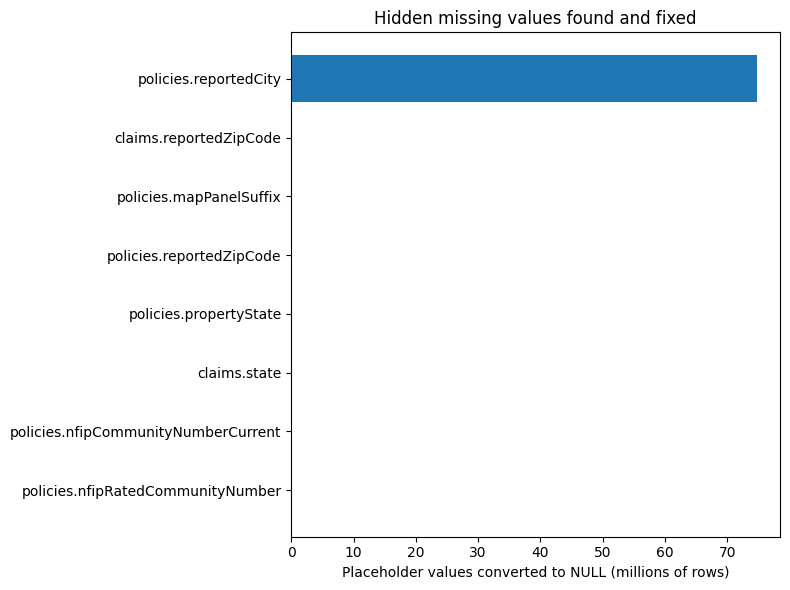

In [94]:
# Step 4.2e Hidden missing values made visible: top 15 columns
top = (before_after[before_after["placeholder_n_raw"] > 0]
       .nlargest(15, "placeholder_n_raw")
       .assign(label=lambda d: d["table"].str.replace("raw_", "") + "." + d["column"]))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["label"], top["placeholder_n_raw"] / 1e6)
ax.set_xlabel("Placeholder values converted to NULL (millions of rows)")
ax.set_title("Hidden missing values found and fixed")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(REPORTS / "fig_placeholders_fixed.png", dpi=150)

In [95]:
# Step 4.2f Save
before_after.to_csv(REPORTS / "dq_before_after.csv", index=False)
ba_summary.to_csv(REPORTS / "dq_before_after_summary.csv", index=False)

#### 4.3 Row reconciliation
Raw rows minus removed rows should equal clean rows for every table. Every difference must appear in the cleaning log.

In [96]:
# Step 4.3a Rows removed, according to the log (log table names are short: "claims", "disasters")
log_df = log.to_frame()
log_df["rows_affected"] = pd.to_numeric(log_df["rows_affected"], errors="coerce")

removal = log_df[log_df["rule"].str.contains("remove|drop row", case=False, na=False)]
removed_by_log = removal.groupby("table")["rows_affected"].sum().rename("removed_by_log")
removal[["table", "column", "rule", "rows_affected"]]

,table,column,rule,rows_affected
0,disasters,ALL,remove exact duplicates (keep lowest id),13
1,claims,ALL,remove exact duplicates (keep lowest id),11382


In [97]:
# Step 4.3b raw - removed = clean ?
recon = row_counts.copy()                                  # from 4.2d
recon["table_short"] = recon["table"].map(CleaningLog.short_name)
recon["removed_by_log"] = recon["table_short"].map(removed_by_log).fillna(0).astype(int)
recon["expected_clean"] = recon["rows_raw"] - recon["removed_by_log"]
recon["difference"]     = recon["rows_clean"] - recon["expected_clean"]
recon["reconciled"]     = recon["difference"] == 0
recon[["table", "rows_raw", "removed_by_log", "expected_clean", "rows_clean", "difference", "reconciled"]]

,table,rows_raw,removed_by_log,expected_clean,rows_clean,difference,reconciled
0,raw_policies,74739461,0,74739461,74739461,0,True
1,raw_claims,2725989,11382,2714607,2714607,0,True
2,raw_community,25133,0,25133,25133,0,True
3,raw_disasters,70599,13,70586,70586,0,True


In [98]:
# Step 4.3c The state lookup has one row per state (otherwise the policies join would duplicate rows)
con.sql("SELECT state, COUNT(*) FROM state_fips GROUP BY 1 HAVING COUNT(*) > 1").df()   # expect empty

,state,count_star()


In [99]:
# Step 4.3d Record ids are still unique after cleaning
for view in ["clean_policies", "clean_claims", "clean_disasters"]:
    total, distinct = con.execute(f"SELECT COUNT(*), COUNT(DISTINCT id) FROM {view}").fetchall()[0]
    print(f"{view}: {total:,} rows, {distinct:,} distinct ids, ok={total == distinct}")

clean_policies: 74,739,461 rows, 74,739,461 distinct ids, ok=True
clean_claims: 2,714,607 rows, 2,714,607 distinct ids, ok=True
clean_disasters: 70,586 rows, 70,586 distinct ids, ok=True


In [100]:
# Step 4.3e Save, and stop here if the row counts don't reconcile
recon.to_csv(REPORTS / "dq_row_reconciliation.csv", index=False)
assert recon["reconciled"].all(), "Row counts don't reconcile; investigate before exporting"

#### 4.4 Spot-check
Compare 20 random rows, raw against clean, by eye.

In [101]:
# Step 4.4a 10 random policies, raw vs clean (compare_rows is documented in src/dq.py)
ids = con.sql("SELECT id FROM raw_policies USING SAMPLE 10 ROWS").df()["id"].tolist()
compare_rows(con, "raw_policies", "clean_policies", ids,
             ["ratedFloodZone", "foundationType", "rateMethod", "reportedZipCode",
              "cancellationVoidanceReasonCode", "policyTermIndicator"])

id,148516368,148525032,148642867,148649405,148652384,148653892,148656869,148657576,148661400,148760772
ratedFloodZone_raw,C,A14,A07,AH,X,X,AE,C,B,AHB
ratedFloodZone_clean,C,A14,A07,AH,X,X,AE,C,B,AHB
foundationType_raw,0,0,0,0,0,0,0,0,0,0
foundationType_clean,None,None,None,None,None,None,None,None,None,None
rateMethod_raw,7,1,1,1,7,7,1,7,7,1
rateMethod_clean,7,1,1,1,7,7,1,7,7,1
reportedZipCode_raw,93257,78377,08202,95035,32312,28590,00727,76240,95961,33326
reportedZipCode_clean,93257,78377,08202,95035,32312,28590,00727,76240,95961,33326
cancellationVoidanceReasonCode_raw,None,None,None,None,None,None,None,None,None,None
cancellationVoidanceReasonCode_clean,None,None,None,None,None,None,None,None,None,None


In [102]:
# Step 4.4b Targeted samples: one query per rule
targets = {
    "foundationType 0 -> NULL":
        "SELECT id FROM raw_policies WHERE foundationType = '0' LIMIT 3",
    "zip lost leading zero":
        "SELECT id FROM raw_policies WHERE LENGTH(CAST(reportedZipCode AS VARCHAR)) = 4 LIMIT 3",
    "invalid policyTermIndicator":
        "SELECT id FROM raw_policies WHERE TRY_CAST(policyTermIndicator AS INTEGER) NOT IN (1, 3, 9) LIMIT 3",
    "cancelled (check category)":
        "SELECT id FROM raw_policies WHERE cancellationVoidanceReasonCode IS NOT NULL LIMIT 3",
}
for label, q in targets.items():
    ids = con.sql(q).df()["id"].tolist()
    print(f"\n### {label}")
    display(compare_rows(con, "raw_policies", "clean_policies", ids,
                         ["foundationType", "reportedZipCode", "policyTermIndicator",
                          "cancellationVoidanceReasonCode"]))
    display(con.sql(f"""SELECT id, zip5, cancel_category, dq_multi_unit, dq_invalid_foundationType
                        FROM clean_policies WHERE id IN ({sql_list(ids)})""").df())


### foundationType 0 -> NULL


id,148636930,148636932,148636933
foundationType_raw,0,0,0
foundationType_clean,None,None,None
reportedZipCode_raw,11901,33060,32951
reportedZipCode_clean,11901,33060,32951
policyTermIndicator_raw,1,1,1
policyTermIndicator_clean,1,1,1
cancellationVoidanceReasonCode_raw,None,None,None
cancellationVoidanceReasonCode_clean,None,None,None


,id,zip5,cancel_category,dq_multi_unit,dq_invalid_foundationType
0,148636933,32951,not_cancelled,False,True
1,148636930,11901,not_cancelled,False,True
2,148636932,33060,not_cancelled,False,True



### zip lost leading zero


id,148576028,149424276,150137731
foundationType_raw,4,4,1
foundationType_clean,4,4,1
reportedZipCode_raw,7758,2879,2050
reportedZipCode_clean,7758,2879,2050
policyTermIndicator_raw,1,1,1
policyTermIndicator_clean,1,1,1
cancellationVoidanceReasonCode_raw,None,None,None
cancellationVoidanceReasonCode_clean,None,None,None


,id,zip5,cancel_category,dq_multi_unit,dq_invalid_foundationType
0,149424276,02879,not_cancelled,False,False
1,148576028,07758,not_cancelled,False,False
2,150137731,02050,not_cancelled,False,False


... (2 outputs left out)

,id,zip5,cancel_category,dq_multi_unit,dq_invalid_foundationType
0,186523170,95833,not_cancelled,False,False
1,189577050,29461,not_cancelled,False,True
2,201745812,70506,not_cancelled,False,False



### cancelled (check category)


id,148637018,148637021,148637063
foundationType_raw,0,0,0
foundationType_clean,None,None,None
reportedZipCode_raw,76034,61748,79907
reportedZipCode_clean,76034,61748,79907
policyTermIndicator_raw,1,1,1
policyTermIndicator_clean,1,1,1
cancellationVoidanceReasonCode_raw,20,50,01
cancellationVoidanceReasonCode_clean,20,50,01


,id,zip5,cancel_category,dq_multi_unit,dq_invalid_foundationType
0,148637021,61748,other,False,True
1,148637063,79907,sold_removed,False,True
2,148637018,76034,other,False,True


In [103]:
# Step 4.4c Community: raw text vs parsed date and flags
con.sql("""
    SELECT currentlyEffectiveMapDate, map_date, map_is_nsfha, map_map_date_future,
           sanctionDate, sanction_date, sanction_is_suspended,
           classRating, crs_class, crs_class_filled
    FROM clean_community
    WHERE currentlyEffectiveMapDate LIKE '%(%'          -- has a legend code
       OR sanctionDate LIKE '%(S)%'
       OR currentlyEffectiveMapDate LIKE '%/7_'         -- 1970s dates: century check
    USING SAMPLE 15 ROWS
""").df()

,currentlyEffectiveMapDate,map_date,map_is_nsfha,map_map_date_future,sanctionDate,sanction_date,sanction_is_suspended,classRating,crs_class,crs_class_filled
0,09/01/87(L),1987-09-01,False,False,None,NaT,False,None,<NA>,10
1,06/20/19(M),2019-06-20,False,False,None,NaT,False,None,<NA>,10
2,(NSFHA),NaT,True,False,None,NaT,False,None,<NA>,10


In [104]:
# Step 4.4d Log the spot-check (write the result only after reading the tables above)
SPOT_CHECK_RESULT = "random + targeted rows for each rule; all matched expectations"   # edit if not
log.add("validation", "spot-check", "manual raw vs clean comparison", SPOT_CHECK_RESULT, 0)

### Section 5. Export
Save the clean tables and the documentation of every cleaning decision.

#### 5.1 Write the clean Parquet files
- Policies partitioned by state and effective year.
- Claims, community and disasters as single files.
- ACS and FRED as Parquet.

In [106]:
# Step 5.1a Export clean policies, one state at a time (keeps memory low)
import shutil

out_pol = PROCESSED / "policies_clean"
# COPY adds files but never deletes old ones, so remove the previous export first
if out_pol.exists():
    shutil.rmtree(out_pol)

con.execute("SET threads = 4")   # fewer threads = less memory in use at once

raw_states = [r[0] for r in con.execute(
    "SELECT DISTINCT propertyState FROM raw_policies ORDER BY 1 NULLS LAST").fetchall()]

for st in raw_states:
    cond = "propertyState IS NULL" if st is None else f"propertyState = '{st}'"
    con.execute(f"CREATE OR REPLACE VIEW raw_policies_st AS SELECT * FROM raw_policies WHERE {cond}")
    con.execute(f"CREATE OR REPLACE VIEW dedup_policies_st AS "
                f"{dedup_sql(con, 'raw_policies_st', DUP_EXCLUDE['raw_policies'], mode='flag')}")
    con.execute(f"""
        COPY (
            SELECT {", ".join(pol_cols)},
                   {special},
                   {", ".join(pol_flags)}
            FROM dedup_policies_st p
            LEFT JOIN state_fips sf ON sf.state = p.propertyState
        )
        TO '{out_pol}'
        (FORMAT PARQUET, PARTITION_BY (propertyState, eff_year), OVERWRITE_OR_IGNORE,
         FILENAME_PATTERN 'part_{{uuid}}', COMPRESSION ZSTD)
    """)
    print(st, "done")

con.execute("RESET threads")
con.execute("DROP VIEW IF EXISTS dedup_policies_st")
con.execute("DROP VIEW IF EXISTS raw_policies_st")

 done
AK done
AL done
AR done
AS done
AZ done
CA done
CO done
CT done
DC done
DE done
FL done
GA done
GU done
HI done
IA done
ID done
IL done
IN done
KS done
KY done
LA done
MA done
MD done
ME done
MI done
MN done
MO done
MP done
MS done
MT done
NC done
ND done
NE done
NH done
NJ done
NM done
NV done
NY done
OH done
OK done
OR done
PA done
PR done
RI done
SC done
SD done
TN done
TX done
UN done
UT done
VA done
VI done
VT done
WA done
WI done
WV done
WY done


In [116]:
# Step 5.1a Export the clean policies into one big file
con.execute(f"""
    COPY (SELECT * FROM read_parquet('{PROCESSED / "policies_clean"}/**/*.parquet', hive_partitioning = true))
    TO '{PROCESSED / "policies_clean_single.parquet"}' (FORMAT PARQUET, COMPRESSION ZSTD)
""")

In [107]:
# Step 5.1b Read one partition back (Florida, 2014-2023)
scalar(con, f"""SELECT COUNT(*) FROM read_parquet('{out_pol}/**/*.parquet', hive_partitioning = true)
                WHERE propertyState = 'FL' AND eff_year BETWEEN 2014 AND 2023""")

12018778

In [108]:
# Step 5.1c Export claims, community, disasters
for view, name in [("clean_claims", "claims_clean"),
                   ("clean_community", "community_clean"),
                   ("clean_disasters", "disasters_clean")]:
    con.execute(f"""COPY (SELECT * FROM {view})
                    TO '{PROCESSED / (name + ".parquet")}'
                    (FORMAT PARQUET, COMPRESSION ZSTD)""")
    print("saved", name)

saved claims_clean
saved community_clean
saved disasters_clean


In [109]:
# Step 5.1d Export ACS and FRED (pandas)
acs_clean.to_parquet(PROCESSED / "acs_clean.parquet", index=False)
fred_monthly.to_parquet(PROCESSED / "fred_monthly.parquet", index=False)

In [110]:
# Step 5.1e Verify the exported files
exports = {
    "raw_policies":  f"read_parquet('{out_pol}/**/*.parquet', hive_partitioning = true)",
    "raw_claims":    f"read_parquet('{PROCESSED / 'claims_clean.parquet'}')",
    "raw_community": f"read_parquet('{PROCESSED / 'community_clean.parquet'}')",
    "raw_disasters": f"read_parquet('{PROCESSED / 'disasters_clean.parquet'}')",
}
expected = recon.set_index("table")["rows_clean"]

for table, src in exports.items():
    n = scalar(con, f"SELECT COUNT(*) FROM {src}")
    print(f"{table}: {n:,} rows (expected {expected[table]:,}) ok={n == expected[table]}")

print("acs:", len(pd.read_parquet(PROCESSED / "acs_clean.parquet")))
print("fred:", len(pd.read_parquet(PROCESSED / "fred_monthly.parquet")))

# File sizes
for p in sorted(PROCESSED.glob("*.parquet")):
    print(f"{p.name}: {p.stat().st_size / 1e6:,.1f} MB")

raw_policies: 74,739,461 rows (expected 74,739,461) ok=True
raw_claims: 2,714,607 rows (expected 2,714,607) ok=True
raw_community: 25,133 rows (expected 25,133) ok=True
raw_disasters: 70,586 rows (expected 70,586) ok=True
acs: 85396
fred: 959
acs_clean.parquet: 3.1 MB
claims_clean.parquet: 197.8 MB
community_clean.parquet: 0.6 MB
disasters_clean.parquet: 4.0 MB
fred_monthly.parquet: 0.0 MB


In [111]:
# Step 5.1f Log
log.add("export", "all tables", "write clean Parquet to data/processed/",
        "policies partitioned by propertyState and eff_year", int(expected["raw_policies"]))

#### 5.2 Save the logs and audits
Save `cleaning_log.csv`, `dq_audit_raw.csv`, `dq_audit_clean.csv` and the before/after table in `reports/`.

In [112]:
# Step 5.2a Final cleaning log
log_df = log.to_frame()
before = len(log_df)
log_df = log_df.drop_duplicates(subset=["table", "column", "rule"], keep="last")
print(f"removed {before - len(log_df)} duplicate log entries (cells run twice)")

log_df["rows_affected"] = pd.to_numeric(log_df["rows_affected"], errors="coerce")
print("entries without a number:")
display(log_df[log_df["rows_affected"].isna()])     # fill these in, or explain them in a note

log_df.insert(0, "step", range(1, len(log_df) + 1))
log_df

removed 0 duplicate log entries (cells run twice)
entries without a number:


,table,column,rule,reason,rows_affected


,step,table,column,rule,reason,rows_affected
0,1,disasters,ALL,remove exact duplicates (keep lowest id),same declaration and county published twice; check the examples in 2.7.3,13
1,2,claims,ALL,remove exact duplicates (keep lowest id),identical claim records under different ids,11382
2,3,policies,ALL,flag dq_identical_group_size (rows kept),"identical after redaction; likely separate units, decided in notebook 04",719387
3,4,policies,asOfDate,drop column,constant: one value in every row,0
4,5,policies,reportedCity,drop column,constant 'NA',0
...,...,...,...,...,...,...
65,66,acs,median_age,sentinel code -> NaN,Census code for 'not available',902
66,67,acs,state/county/tract,build geoid11,join key to policies,0
67,68,fred,all series,resample to monthly mean,align frequencies,0
68,69,validation,spot-check,manual raw vs clean comparison,random + targeted rows for each rule; all matched expectations,0


In [113]:
# Step 5.2b Save logs and audits
log_df.to_csv(REPORTS / "cleaning_log.csv", index=False)
dq_audit_raw.to_csv(REPORTS / "dq_audit_raw.csv", index=False)
dq_audit_clean.to_csv(REPORTS / "dq_audit_clean.csv", index=False)
before_after.to_csv(REPORTS / "dq_before_after.csv", index=False)
recon.to_csv(REPORTS / "dq_row_reconciliation.csv", index=False)

# Compilation of all logs and audits
with pd.ExcelWriter(REPORTS / "data_cleaning_report.xlsx") as xw:
    ba_summary.to_excel(xw, sheet_name="summary", index=False)
    recon.to_excel(xw, sheet_name="row_reconciliation", index=False)
    log_df.to_excel(xw, sheet_name="cleaning_log", index=False)
    before_after.to_excel(xw, sheet_name="before_after", index=False)
    dq_audit_raw.to_excel(xw, sheet_name="audit_raw", index=False)
    dq_audit_clean.to_excel(xw, sheet_name="audit_clean", index=False)

sorted(p.name for p in REPORTS.iterdir())

['cleaning_log.csv',
 'data_cleaning_report.xlsx',
 'dq_allowed_values_check.csv',
 'dq_audit_clean.csv',
 'dq_audit_raw.csv',
 'dq_audit_raw.xlsx',
 'dq_before_after.csv',
 'dq_before_after_summary.csv',
 'dq_constant_raw.csv',
 'dq_geo_format_raw.csv',
 'dq_geo_integrity_raw.csv',
 'dq_geo_state_mismatch_raw.csv',
 'dq_invalid_values_detail.csv',
 'dq_invalid_values_review.csv',
 'dq_missing_raw.csv',
 'dq_plausibility_raw.csv',
 'dq_row_reconciliation.csv',
 'dq_summary_policies_raw.csv',
 'fig_foundation_zero_by_year.png',
 'fig_placeholders_fixed.png',
 'summary_raw_claims.xlsx',
 'summary_raw_community.xlsx',
 'summary_raw_disasters.xlsx',
 'summary_raw_policies.xlsx']

#### 5.3 Cleaning decisions note
Write a short markdown file in `docs/` with the key choices and why: what was dropped, what was flagged, what NULL means in each column where a null carries meaning, and the decisions left for notebook 04.

In [115]:
# Step 5.3 Cleaning decisions note
r = recon.set_index("table")
dropped = before_after.loc[before_after["status"] == "dropped", "column"].tolist()
n_placeholders = int(before_after["placeholder_n_raw"].fillna(0).sum())
n_invalid = int(before_after["invalid_n_raw"].fillna(0).sum())

note = f"""# Data cleaning decisions (notebook 02)

## Summary
- Policies: {r.loc['raw_policies','rows_raw']:,} rows in, {r.loc['raw_policies','rows_clean']:,} out (no rows removed; problems flagged with `dq_` columns).
- Claims: {r.loc['raw_claims','rows_raw']:,} in, {r.loc['raw_claims','rows_clean']:,} out (exact duplicates removed).
- Disasters: {r.loc['raw_disasters','rows_raw']:,} in, {r.loc['raw_disasters','rows_clean']:,} out (exact duplicates removed).
- Community: {r.loc['raw_community','rows_raw']:,} in, {r.loc['raw_community','rows_clean']:,} out.
- {n_placeholders:,} placeholder values ("None", "NA", ...) converted to NULL.
- {n_invalid:,} values outside the dictionary's legal codes set to NULL (each flagged with `dq_invalid_<column>`).
- Columns dropped: {", ".join(dropped) or "none"}.

## Principles
- Raw files are never edited; every rule is code plus a cleaning-log entry.
- Flag, don't delete: rows are only removed when they are exact duplicates.
- No imputation here; missing values are handled in notebook 05, fitted on training data only.

## Key decisions
- **Policy duplicates kept: to be removed later as we get the policyID** ...
- **foundationType code 0: transform it into NULL** ...
- **rateMethod RE: kept** ...
- **Cancellation codes: untouched but we have classified whether it is lapsed, duplicate, etc.** ...
- **Community dates and legend codes: kept** ...
- **CRS class "None": kept** ...

## Where NULL has a meaning
| Column | NULL means |
|---|---|
| cancellationVoidanceReasonCode | not cancelled |
| classRating / crs_class | community not in CRS (no discount) |
| sanctionDate | never sanctioned |
| currentlyEffectiveMapDate | see legend flags (NSFHA, N/A) |
| foundationType | not reported (code 0 in the raw data; see dq_invalid_foundationType) |

## Left for later notebooks
- Notebook 03: policy key and linkage; claims with incomplete keys can't be linked.
- Notebook 04: whether to exclude multi-unit and identical policy rows; `dq_` flag exclusions.
- Notebook 05: ACS tract-boundary mismatch (2010 vs 2020); FRED publication lag; statewide disasters.
"""
(DOCS / "cleaning_decisions.md").write_text(note)
print(note)

# Data cleaning decisions (notebook 02)

## Summary
- Policies: 74,739,461 rows in, 74,739,461 out (no rows removed; problems flagged with `dq_` columns).
- Claims: 2,725,989 in, 2,714,607 out (exact duplicates removed).
- Disasters: 70,599 in, 70,586 out (exact duplicates removed).
- Community: 25,133 in, 25,133 out.
- 74,806,197 placeholder values ("None", "NA", ...) converted to NULL.
- 37,680,423 values outside the dictionary's legal codes set to NULL (each flagged with `dq_invalid_<column>`).
- Columns dropped: asOfDate, numberOfFloorsInTheInsuredBuilding, reportedCity, lastRefresh, asOfDate, reportedCity.

## Principles
- Raw files are never edited; every rule is code plus a cleaning-log entry.
- Flag, don't delete: rows are only removed when they are exact duplicates.
- No imputation here; missing values are handled in notebook 05, fitted on training data only.

## Key decisions
- **Policy duplicates kept: to be removed later as we get the policyID** ...
- **foundationType code 